
# Proyecto Final 
## Identificación de subgrupos moleculares en cáncer de hígado mediante aprendizaje no supervisado

**Juan Angel Galván Navarro**
---

# 1. Planteamiento del problema y contexto de los datos

### El problema

El carcinoma hepatocelular (HCC) es el tipo más común de cáncer primario de hígado. Una de las dificultades para estudiarlo es que no todos los tumores presentan las mismas características moleculares. Aunque dos pacientes tengan el mismo diagnóstico, sus tumores pueden mostrar diferencias importantes en la actividad de sus genes, lo que podría relacionarse con el desarrollo de la enfermedad y su pronóstico (The Cancer Genome Atlas Research Network, 2017).

Esta diversidad representa un problema para comprender el cáncer como una sola enfermedad. Si existen grupos de tumores con características moleculares diferentes, identificarlos podría ayudar a entender mejor su comportamiento.

Investigaciones anteriores, como la realizada por The Cancer Genome Atlas Research Network (2017), han identificado subtipos moleculares de carcinoma hepatocelular mediante el análisis de información genómica. Esto demuestra la importancia de estudiar las diferencias moleculares entre pacientes y plantea la posibilidad de encontrar patrones utilizando técnicas de aprendizaje no supervisado.

### Qué se busca aprender

El objetivo de este proyecto es identificar posibles subgrupos de cáncer de hígado a partir de los patrones de expresión génica de muestras tumorales.

El propósito no es desarrollar un modelo de diagnóstico, sino explorar la estructura molecular de los tumores y determinar si las agrupaciones encontradas tienen alguna interpretación clínica.

### Origen de los datos

Los datos provienen de **The Cancer Genome Atlas (TCGA)**, un proyecto de investigación que reúne información molecular y clínica de distintos tipos de cáncer. Se utiliza específicamente la cohorte **GDC TCGA Liver Cancer (LIHC)**, disponible mediante la plataforma UCSC Xena (Goldman et al., 2020).

Para el análisis se dispone de cuatro archivos:

- **STAR-TPM:** matriz de expresión génica obtenida mediante secuenciación de ARN (RNA-seq), que permite analizar la actividad de miles de genes en cada muestra.
- **ID/Gene Mapping:** archivo que relaciona los identificadores de Ensembl con los nombres de los genes.
- **Clinical (Phenotype):** información sobre las características clínicas y demográficas de los pacientes.
- **Survival:** información relacionada con la supervivencia y el seguimiento de los pacientes.

La expresión génica será la única información utilizada para construir los grupos. Los datos clínicos y de supervivencia se incorporarán posteriormente para evaluar si las agrupaciones obtenidas presentan diferencias relevantes.

### Justificación del aprendizaje no supervisado

A diferencia de los problemas de clasificación, en este proyecto no se cuenta con una etiqueta que indique a qué subtipo molecular pertenece cada muestra. Por esta razón, se utiliza aprendizaje no supervisado, que permite encontrar similitudes y diferencias directamente a partir de los datos.

El principal desafío es la alta dimensionalidad: cada muestra contiene información de miles de genes, muchos de los cuales pueden tener expresiones similares o aportar poca información para distinguir tumores.

Para abordar este problema se utilizará Análisis de Componentes Principales (PCA), seguido de los algoritmos K-Means y Hierarchical Clustering.

Los grupos encontrados no se considerarán automáticamente subtipos clínicos. Primero será necesario evaluar qué tan consistentes son, qué genes los diferencian y si presentan asociaciones con las variables clínicas disponibles.

De esta manera, el proyecto busca pasar de una matriz de expresión génica difícil de interpretar a una representación más sencilla que permita comprender mejor la diversidad molecular del carcinoma hepatocelular.



# 2. Exploración y comprensión del conjunto de datos

### Carga y estructura de los datos

Se revisará la cantidad de muestras y genes disponibles, los tipos de información y la correspondencia entre los identificadores de expresión génica y los nombres de los genes.

También se identificarán los tipos de muestras presentes en la base, ya que TCGA puede incluir tanto tejido tumoral como tejido normal. Esta distinción es importante porque el objetivo del proyecto es encontrar diferencias moleculares entre tumores, no solamente distinguir tejido sano de tejido canceroso.


In [2]:

import pandas as pd
import numpy as np
from pathlib import Path

DATASET = Path("dataset")

# Cargar matriz de expresión génica
expresion = pd.read_csv(
    DATASET / "TCGA-LIHC.star_tpm.tsv.gz",
    sep="\t",
    index_col=0
)
expresion = expresion.astype(np.float32)
# Cargar identificadores y nombres de genes
mapping = pd.read_csv(
    DATASET / "gencode.v36.annotation.gtf.gene.probemap",
    sep="\t"
)

print("MATRIZ DE EXPRESIÓN GÉNICA")
print(f"Genes: {expresion.shape[0]:,}")
print(f"Muestras: {expresion.shape[1]:,}")
print(f"Tipo de datos: {expresion.dtypes.value_counts().to_dict()}")

print("\nPRIMEROS REGISTROS")
display(expresion.iloc[:5, :5])

print("\nID/GENE MAPPING")
print(f"Genes en mapping: {len(mapping):,}")
display(mapping.head())


MATRIZ DE EXPRESIÓN GÉNICA
Genes: 60,660
Muestras: 424
Tipo de datos: {dtype('float32'): 424}

PRIMEROS REGISTROS


,TCGA-5R-AA1C-01A,TCGA-ED-A66Y-01A,TCGA-DD-AAEI-01A,TCGA-ED-A8O5-01A,TCGA-DD-A3A2-11A
Ensembl_ID,,,,,
ENSG00000000003.15,6.863447,5.221413,5.315668,5.766399,5.427251
ENSG00000000005.6,0.254836,0.000000,0.051581,0.157044,0.264957
ENSG00000000419.13,6.909410,5.999260,5.328535,5.013637,5.325527
ENSG00000000457.14,3.362007,3.694713,1.576909,3.533090,1.848197
ENSG00000000460.17,4.462321,2.120053,0.805045,2.011424,0.408821



ID/GENE MAPPING
Genes en mapping: 60,660


,id,gene,chrom,chromStart,chromEnd,strand
0,ENSG00000223972.5,DDX11L1,chr1,11869,14409,+
1,ENSG00000227232.5,WASH7P,chr1,14404,29570,-
2,ENSG00000278267.1,MIR6859-1,chr1,17369,17436,-
3,ENSG00000243485.5,MIR1302-2HG,chr1,29554,31109,+
4,ENSG00000284332.1,MIR1302-2,chr1,30366,30503,+


In [3]:

# Verificar correspondencia de identificadores
genes_expresion = set(expresion.index)
genes_mapping = set(mapping["id"])

print("CORRESPONDENCIA DE GENES")
print(f"Genes con mapping: {len(genes_expresion & genes_mapping):,}")
print(f"Genes sin mapping: {len(genes_expresion - genes_mapping):,}")

# Identificar tipos de muestras según códigos TCGA
tipos = {
    "01": "Tumor primario",
    "02": "Tumor recurrente",
    "11": "Tejido normal"
}

muestras = pd.DataFrame({
    "sample_id": expresion.columns
})

muestras["tipo_codigo"] = (
    muestras["sample_id"].str.split("-").str[3].str[:2]
)

muestras["tipo_muestra"] = (
    muestras["tipo_codigo"].map(tipos).fillna("Otro")
)

print("\nDISTRIBUCIÓN DE MUESTRAS")
display(
    muestras["tipo_muestra"]
    .value_counts()
    .rename_axis("Tipo de muestra")
    .reset_index(name="Cantidad")
)

print("\nIDENTIFICADORES ÚNICOS")
print("Muestras únicas:", muestras["sample_id"].nunique())
print(
    "Pacientes únicos:",
    muestras["sample_id"].str.split("-").str[:3]
    .str.join("-").nunique()
)


CORRESPONDENCIA DE GENES
Genes con mapping: 60,660
Genes sin mapping: 0

DISTRIBUCIÓN DE MUESTRAS


,Tipo de muestra,Cantidad
0,Tumor primario,371
1,Tejido normal,50
2,Tumor recurrente,3



IDENTIFICADORES ÚNICOS
Muestras únicas: 424
Pacientes únicos: 371



### Interpretación de la estructura de los datos

La base contiene 60,660 genes y 424 muestras correspondientes a 371 pacientes diferentes. Esto representa un problema de alta dimensionalidad, ya que existen muchas más variables que observaciones.

El archivo de mapeo permitió identificar el 100% de los genes, por lo que podremos relacionar los resultados posteriores con nombres de genes específicos.

De las 424 muestras, 371 corresponden a tumores primarios, 50 a tejido normal y 3 a tumores recurrentes.

Para este proyecto se propone trabajar únicamente con los tumores primarios, ya que buscamos identificar diferencias moleculares entre tumores. Incluir tejido normal podría hacer que los modelos separen principalmente muestras sanas y cancerosas, en lugar de encontrar posibles subgrupos dentro del cáncer.


In [4]:

# Cargar datos clínicos y supervivencia
clinico = pd.read_csv(
    DATASET / "TCGA-LIHC.clinical.tsv.gz",
    sep="\t",
    low_memory=False
)

supervivencia = pd.read_csv(
    DATASET / "TCGA-LIHC.survival.tsv.gz",
    sep="\t"
)

print("DATOS CLÍNICOS")
print("Dimensiones:", clinico.shape)
print("\nVariables disponibles:")
print(clinico.columns.tolist())
display(clinico.head(3))

print("\nDATOS DE SUPERVIVENCIA")
print("Dimensiones:", supervivencia.shape)
display(supervivencia.head(3))

# Comprobar que cada tumor primario corresponda a un paciente distinto
primarias = muestras[muestras["tipo_codigo"] == "01"].copy()
primarias["paciente"] = (
    primarias["sample_id"]
    .str.split("-").str[:3].str.join("-")
)

print("\nVERIFICACIÓN DE TUMORES PRIMARIOS")
print("Muestras:", len(primarias))
print("Pacientes únicos:", primarias["paciente"].nunique())
print("Muestras duplicadas por paciente:",
      primarias["paciente"].duplicated().sum())


DATOS CLÍNICOS
Dimensiones: (439, 83)

Variables disponibles:
['sample', 'id', 'disease_type', 'case_id', 'submitter_id', 'primary_site', 'alcohol_history.exposures', 'race.demographic', 'gender.demographic', 'ethnicity.demographic', 'vital_status.demographic', 'age_at_index.demographic', 'days_to_birth.demographic', 'year_of_birth.demographic', 'year_of_death.demographic', 'primary_site.project', 'project_id.project', 'disease_type.project', 'name.project', 'name.program.project', 'tissue_source_site_id.tissue_source_site', 'code.tissue_source_site', 'name.tissue_source_site', 'project.tissue_source_site', 'bcr_id.tissue_source_site', 'days_to_death.demographic', 'entity_submitter_id.annotations', 'notes.annotations', 'submitter_id.annotations', 'classification.annotations', 'entity_id.annotations', 'created_datetime.annotations', 'annotation_id.annotations', 'entity_type.annotations', 'updated_datetime.annotations', 'case_id.annotations', 'state.annotations', 'category.annotations', 

,sample,id,disease_type,case_id,submitter_id,primary_site,alcohol_history.exposures,race.demographic,gender.demographic,ethnicity.demographic,...,sample_type.samples,composition.samples,days_to_collection.samples,initial_weight.samples,preservation_method.samples,pathology_report_uuid.samples,oct_embedded.samples,specimen_type.samples,is_ffpe.samples,tissue_type.samples
0,TCGA-DD-A73C-01A,79f9331c-9e00-4277-a9d1-7c848e132134,Adenomas and Adenocarcinomas,79f9331c-9e00-4277-a9d1-7c848e132134,TCGA-DD-A73C,Liver and intrahepatic bile ducts,Not Reported,white,female,not hispanic or latino,...,Primary Tumor,Not Reported,288.0,160.0,Unknown,FE051CD7-9C34-4A45-934C-DD8BB00C717A,False,Solid Tissue,False,Tumor
1,TCGA-5C-AAPD-01A,7a6162a4-1166-4310-84cd-ffc2b06f124c,Adenomas and Adenocarcinomas,7a6162a4-1166-4310-84cd-ffc2b06f124c,TCGA-5C-AAPD,Liver and intrahepatic bile ducts,Not Reported,asian,male,not hispanic or latino,...,Primary Tumor,Not Reported,55.0,140.0,OCT,E4DB31C4-89F3-4D8D-A32E-B42C599904E1,True,Solid Tissue,False,Tumor
2,TCGA-ZS-A9CE-01A,7bdc5f86-4d7d-4f1f-bc23-ab51fa9fb947,Adenomas and Adenocarcinomas,7bdc5f86-4d7d-4f1f-bc23-ab51fa9fb947,TCGA-ZS-A9CE,Liver and intrahepatic bile ducts,Not Reported,white,female,not hispanic or latino,...,Primary Tumor,Not Reported,967.0,10.0,OCT,35A87F65-19F9-4C03-8A82-FFBF2C3C568A,True,Solid Tissue,False,Tumor



DATOS DE SUPERVIVENCIA
Dimensiones: (433, 4)


,sample,OS.time,OS,_PATIENT
0,TCGA-FV-A495-01A,1.0,0,TCGA-FV-A495
1,TCGA-ED-A7PX-01A,6.0,0,TCGA-ED-A7PX
2,TCGA-ED-A7PZ-01A,6.0,0,TCGA-ED-A7PZ



VERIFICACIÓN DE TUMORES PRIMARIOS
Muestras: 371
Pacientes únicos: 371
Muestras duplicadas por paciente: 0



### Información clínica y selección de muestras

El archivo clínico contiene 439 registros y 83 variables, mientras que el archivo de supervivencia tiene 433 registros y 4 variables. Entre la información disponible se encuentran la edad, el sexo, el estadio del cáncer, el grado tumoral y datos relacionados con la supervivencia.

También se comprobó que las 371 muestras de tumores primarios corresponden a 371 pacientes diferentes, sin duplicados.

Para el análisis se utilizarán únicamente estas 371 muestras, excluyendo las 50 de tejido normal y las 3 de tumores recurrentes. Esta selección permitirá concentrar el agrupamiento en las diferencias moleculares entre tumores primarios.

Los datos clínicos se conservarán por separado y se utilizarán únicamente después de generar los clusters.


In [5]:

# Seleccionar identificadores de tumores primarios
ids_primarios = primarias["sample_id"]

# Comparar muestras con los archivos clínico y de supervivencia
ids_clinicos = set(clinico["sample"])
ids_supervivencia = set(supervivencia["sample"])

print("CORRESPONDENCIA ENTRE DATASETS")
print("Tumores primarios:", len(ids_primarios))

print("Con información clínica:",
      ids_primarios.isin(ids_clinicos).sum())

print("Con información de supervivencia:",
      ids_primarios.isin(ids_supervivencia).sum())

print("Con ambos archivos:",
      (ids_primarios.isin(ids_clinicos) &
       ids_primarios.isin(ids_supervivencia)).sum())

# Crear matriz inicial de tumores primarios
expresion_primaria = expresion.loc[:, ids_primarios].copy()

print("\nMATRIZ SELECCIONADA")
print("Genes:", expresion_primaria.shape[0])
print("Tumores primarios:", expresion_primaria.shape[1])


CORRESPONDENCIA ENTRE DATASETS
Tumores primarios: 371
Con información clínica: 371
Con información de supervivencia: 365
Con ambos archivos: 365

MATRIZ SELECCIONADA
Genes: 60660
Tumores primarios: 371



### Correspondencia entre los conjuntos de datos

Se comprobó que los 371 tumores primarios tienen información clínica disponible. De estos, 365 también cuentan con registros de supervivencia, mientras que 6 no tienen correspondencia en ese archivo.

Se conservarán los 371 tumores primarios para el análisis de expresión génica, ya que los datos clínicos y de supervivencia no se utilizarán para construir los clusters. Los registros sin información de supervivencia se excluirán únicamente de los análisis que requieran esa variable.



### Calidad y distribución de la expresión génica

Antes de aplicar PCA y clustering, se revisará la calidad de los valores de expresión génica. Se buscarán valores faltantes, genes sin expresión y diferencias importantes entre muestras.

Este análisis permitirá determinar si es necesario filtrar genes o transformar los datos antes de construir los modelos.


CALIDAD DE LOS DATOS
Valores faltantes: 0
Genes con valores faltantes: 0
Genes con expresión cero en todas las muestras: 4,392
Genes con más del 90% de valores cero: 20,974

ESTADÍSTICAS DE EXPRESIÓN
Mínimo: 0.0000
Mediana: 0.0000
Media: 0.8934
Máximo: 17.4027


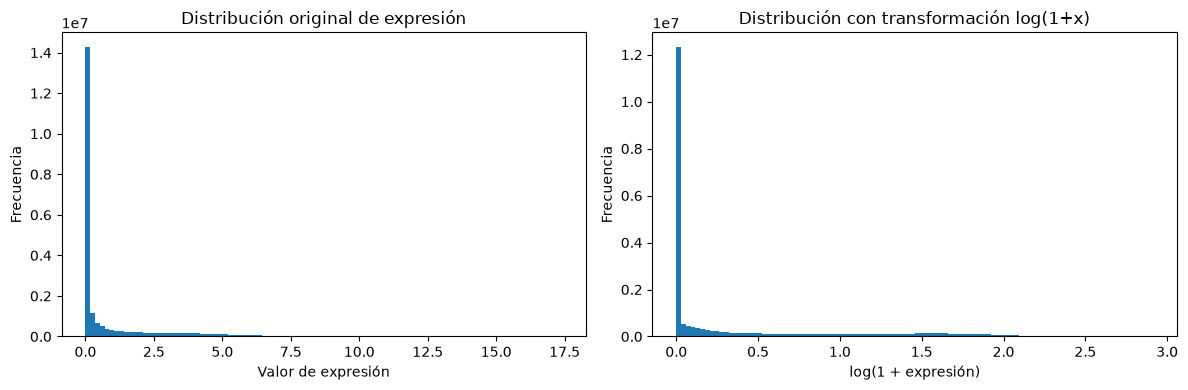

In [6]:

import matplotlib.pyplot as plt

# Valores faltantes
nulos = expresion_primaria.isna().sum().sum()
genes_con_nulos = expresion_primaria.isna().any(axis=1).sum()

# Genes sin expresión
genes_cero = (expresion_primaria == 0).all(axis=1).sum()

# Proporción de ceros por gen
proporcion_ceros = (expresion_primaria == 0).mean(axis=1)

# Estadísticas generales
valores = expresion_primaria.to_numpy()

print("CALIDAD DE LOS DATOS")
print(f"Valores faltantes: {nulos:,}")
print(f"Genes con valores faltantes: {genes_con_nulos:,}")
print(f"Genes con expresión cero en todas las muestras: {genes_cero:,}")
print(f"Genes con más del 90% de valores cero: {(proporcion_ceros > 0.90).sum():,}")

print("\nESTADÍSTICAS DE EXPRESIÓN")
print(f"Mínimo: {np.nanmin(valores):.4f}")
print(f"Mediana: {np.nanmedian(valores):.4f}")
print(f"Media: {np.nanmean(valores):.4f}")
print(f"Máximo: {np.nanmax(valores):.4f}")

# Distribución de los valores de expresión
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(valores.ravel(), bins=100)
axes[0].set_title("Distribución original de expresión")
axes[0].set_xlabel("Valor de expresión")
axes[0].set_ylabel("Frecuencia")

axes[1].hist(np.log1p(valores).ravel(), bins=100)
axes[1].set_title("Distribución con transformación log(1+x)")
axes[1].set_xlabel("log(1 + expresión)")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()



### Interpretación de la calidad de los datos

La matriz de expresión génica no presenta valores faltantes, por lo que no será necesario aplicar métodos de imputación.

Sin embargo, se identificaron 4,392 genes con expresión cero en todas las muestras y 20,974 genes con valores cero en más del 90% de los tumores. Esto indica que una parte importante de los genes presenta poca o ninguna expresión en la mayoría de las muestras.

La distribución también muestra una concentración de valores cercanos a cero y una cantidad menor de valores elevados. De acuerdo con la documentación de UCSC Xena, los datos STAR-TPM ya están transformados mediante log2(TPM+1), por lo que no se aplicará otra transformación logarítmica.

Para preparar los datos será necesario considerar un filtrado de genes con expresión muy baja, buscando reducir la cantidad de variables que aportan poca información al análisis.



### Distribución de expresión y detección de valores atípicos

Además de revisar los genes, es importante analizar las diferencias entre muestras. Algunas pueden presentar niveles de expresión muy distintos al resto, lo que podría influir en los resultados de PCA y clustering.

Para revisar esto se compararán las distribuciones de expresión de los tumores y la cantidad de genes con expresión detectable en cada muestra.


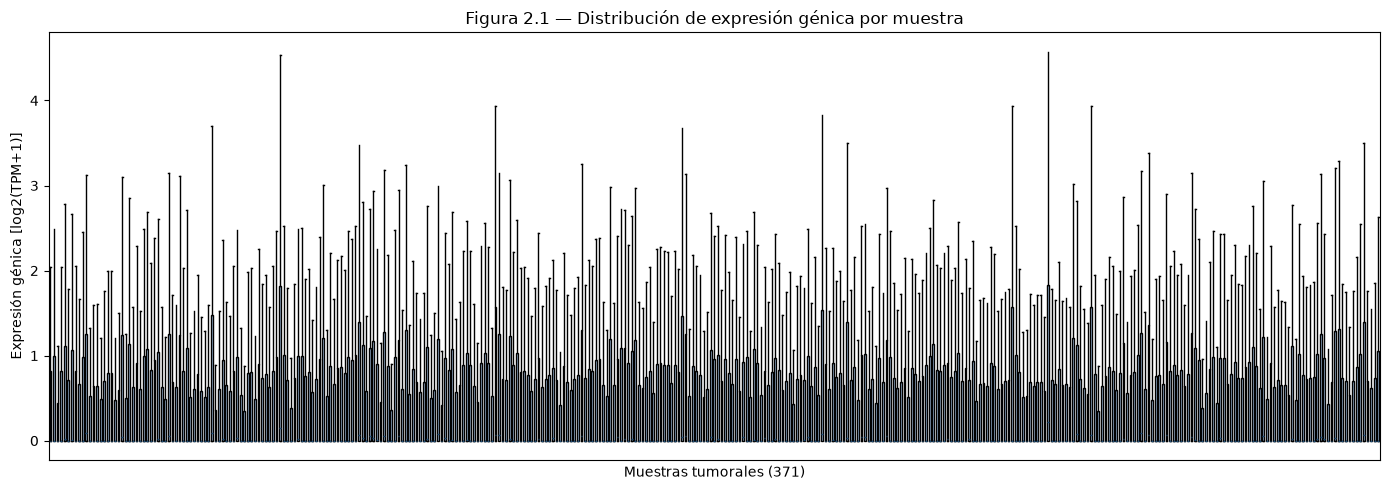

In [7]:

# Distribución de expresión por muestra
fig, ax = plt.subplots(figsize=(14, 5))

ax.boxplot(
    expresion_primaria.to_numpy(),
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor="#a8c8eb"),
    medianprops=dict(color="#1f4e79")
)

ax.set_title("Figura 2.1 — Distribución de expresión génica por muestra")
ax.set_xlabel("Muestras tumorales (371)")
ax.set_ylabel("Expresión génica [log2(TPM+1)]")
ax.set_xticks([])

plt.tight_layout()
plt.show()


### Detección de valores atípicos mediante IQR

Para identificar muestras con cantidades inusuales de genes detectados, se utilizó el rango intercuartílico (IQR), un método sugerido con apoyo de inteligencia artificial.

Según Khan Academy (s.f.), el IQR mide la dispersión del 50% central de los datos y se calcula como la diferencia entre el tercer cuartil (Q3) y el primer cuartil (Q1).

Para detectar posibles valores atípicos se utilizó el criterio del NIST (s.f.), que establece límites inferiores y superiores mediante Q1 − 1.5 × IQR y Q3 + 1.5 × IQR.

Se eligió este método porque permite identificar observaciones alejadas de la distribución central sin asumir una distribución normal. Las muestras identificadas se conservarán, ya que un valor atípico no necesariamente representa un error.

GENES DETECTADOS POR MUESTRA


count      371.00
mean     28431.45
std       2388.93
min      22286.00
25%      26778.50
50%      28513.00
75%      29816.50
max      37780.00
dtype: float64


Límite inferior IQR: 22222
Límite superior IQR: 34374
Muestras potencialmente atípicas: 5


,Genes detectados
TCGA-CC-5263-01A,34564
TCGA-CC-A1HT-01A,34739
TCGA-BC-4073-01B,35101
TCGA-G3-A7M6-01A,35461
TCGA-G3-A7M9-01A,37780


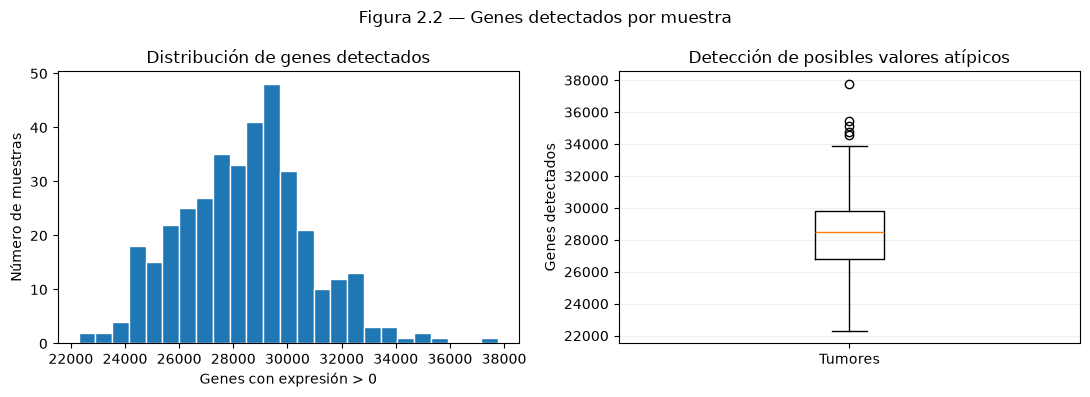

In [8]:

# Cantidad de genes con expresión mayor que cero por muestra
genes_detectados = (expresion_primaria > 0).sum(axis=0)

# Estadísticas generales
print("GENES DETECTADOS POR MUESTRA")
display(genes_detectados.describe().round(2))

# Identificar posibles muestras atípicas mediante IQR
q1 = genes_detectados.quantile(0.25)
q3 = genes_detectados.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicas = genes_detectados[
    (genes_detectados < limite_inferior) |
    (genes_detectados > limite_superior)
]

print(f"\nLímite inferior IQR: {limite_inferior:.0f}")
print(f"Límite superior IQR: {limite_superior:.0f}")
print(f"Muestras potencialmente atípicas: {len(atipicas)}")

if len(atipicas) > 0:
    display(
        atipicas.sort_values()
        .rename("Genes detectados")
        .to_frame()
    )

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(genes_detectados, bins=25, edgecolor="white")
axes[0].set_title("Distribución de genes detectados")
axes[0].set_xlabel("Genes con expresión > 0")
axes[0].set_ylabel("Número de muestras")

axes[1].boxplot(genes_detectados, tick_labels=["Tumores"])
axes[1].set_title("Detección de posibles valores atípicos")
axes[1].set_ylabel("Genes detectados")
axes[1].grid(axis="y", alpha=0.2)

fig.suptitle("Figura 2.2 — Genes detectados por muestra")
plt.tight_layout()
plt.show()



### Interpretación de las distribuciones y valores atípicos

La Figura 2.1 muestra que las muestras tumorales tienen distribuciones de expresión relativamente similares, con una concentración importante de valores bajos. Algunas presentan mayor dispersión, pero no se observa una separación clara entre grupos.

En la Figura 2.2 se observa que las muestras tienen un promedio de 28,431 genes detectados, con una desviación estándar de aproximadamente 2,389 genes. La cantidad varía entre 22,286 y 37,780 genes por muestra.

Utilizando el criterio IQR se identificaron cinco muestras potencialmente atípicas, todas con cantidades de genes detectados superiores al límite establecido.

Sin embargo, estos valores no necesariamente representan errores, ya que podrían reflejar diferencias biológicas entre tumores. Por esta razón, se conservarán todas las muestras y se revisará posteriormente si estas observaciones influyen de manera importante en los resultados de PCA y clustering.



### Exploración de las variables clínicas

Además de la expresión génica, la base contiene información clínica que puede ayudar a interpretar los grupos encontrados posteriormente.

Se revisarán cuatro características: edad, sexo, estadio patológico y grado tumoral. También se analizará la cantidad de valores faltantes en cada variable, ya que esto podría limitar las comparaciones clínicas entre los clusters.

Por ahora, estas variables se utilizarán únicamente para conocer las características generales de los pacientes.


In [11]:

# Seleccionar registros clínicos de los tumores primarios
clinico_primario = clinico[
    clinico["sample"].isin(primarias["sample_id"])
].copy()

# Variables clínicas de interés
columnas_clinicas = {
    "sample": "Muestra",
    "age_at_index.demographic": "Edad",
    "gender.demographic": "Sexo",
    "ajcc_pathologic_stage.diagnoses": "Estadio",
    "tumor_grade.diagnoses": "Grado tumoral",
    "vital_status.demographic": "Estado vital"
}

datos_clinicos = (
    clinico_primario[list(columnas_clinicas)]
    .rename(columns=columnas_clinicas)
    .copy()
)

# Revisar posibles duplicados
print("REGISTROS CLÍNICOS")
print("Registros:", len(datos_clinicos))
print("Muestras únicas:", datos_clinicos["Muestra"].nunique())

# Convertir edad a numérica
datos_clinicos["Edad"] = pd.to_numeric(
    datos_clinicos["Edad"], errors="coerce"
)

# Normalizar códigos de valores no disponibles
datos_clinicos = datos_clinicos.replace(
    ["not reported", "not available", "unknown",
     "Not Reported", "Not Available", "Unknown", ""],
    np.nan
)

print("\nVALORES FALTANTES")
faltantes = datos_clinicos.isna().sum()

tabla_faltantes = pd.DataFrame({
    "Faltantes": faltantes,
    "Porcentaje": (faltantes / len(datos_clinicos) * 100).round(2)
})

display(tabla_faltantes)

print("\nPRIMEROS REGISTROS")
display(datos_clinicos.head())


REGISTROS CLÍNICOS
Registros: 371
Muestras únicas: 371

VALORES FALTANTES


/var/folders/4v/zycbzfcs4kl3xy9rljgv391c0000gn/T/ipykernel_6946/6763633.py:33: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  datos_clinicos = datos_clinicos.replace(


,Faltantes,Porcentaje
Muestra,0,0.00
Edad,1,0.27
Sexo,0,0.00
Estadio,24,6.47
Grado tumoral,371,100.00
Estado vital,1,0.27



PRIMEROS REGISTROS


,Muestra,Edad,Sexo,Estadio,Grado tumoral,Estado vital
0,TCGA-DD-A73C-01A,65.0,female,Stage IIIA,NaN,Alive
1,TCGA-5C-AAPD-01A,61.0,male,Stage II,NaN,Alive
2,TCGA-ZS-A9CE-01A,79.0,female,Stage II,NaN,Alive
3,TCGA-HP-A5N0-01A,90.0,female,NaN,NaN,Dead
4,TCGA-DD-AAVQ-01A,38.0,male,Stage I,NaN,Alive


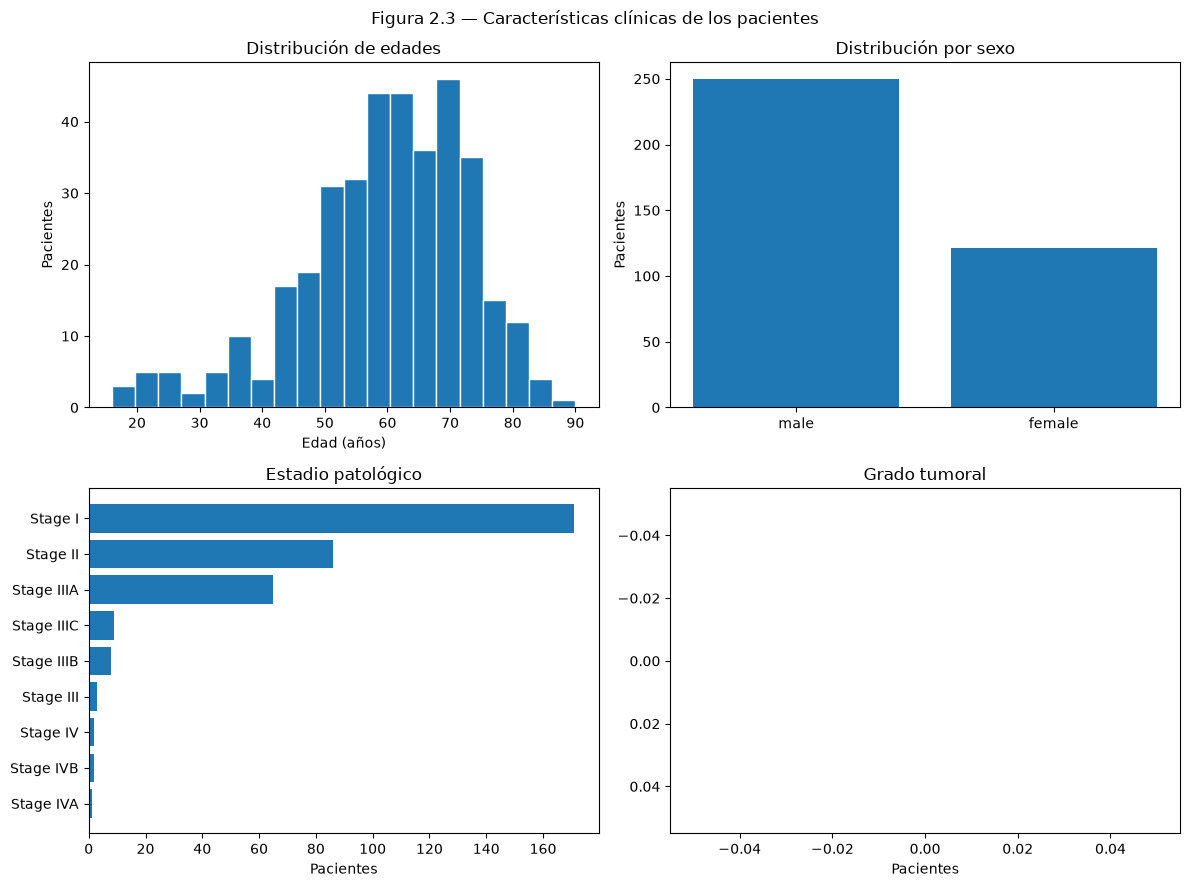

ESTADÍSTICAS DE EDAD


count    370.00
mean      59.44
std       13.52
min       16.00
25%       51.25
50%       61.00
75%       69.00
max       90.00
Name: Edad, dtype: float64


DISTRIBUCIONES CATEGÓRICAS

Sexo


Sexo
male      250
female    121
Name: count, dtype: int64


Estadio


Estadio
Stage I       171
Stage II       86
Stage IIIA     65
NaN            24
Stage IIIC      9
Stage IIIB      8
Stage III       3
Stage IV        2
Stage IVB       2
Stage IVA       1
Name: count, dtype: int64


Grado tumoral


Grado tumoral
NaN    371
Name: count, dtype: int64


Estado vital


Estado vital
Alive    240
Dead     130
NaN        1
Name: count, dtype: int64

In [12]:

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Edad
axes[0, 0].hist(
    datos_clinicos["Edad"].dropna(),
    bins=20,
    edgecolor="white"
)
axes[0, 0].set_title("Distribución de edades")
axes[0, 0].set_xlabel("Edad (años)")
axes[0, 0].set_ylabel("Pacientes")

# Sexo
sexo = datos_clinicos["Sexo"].value_counts()
axes[0, 1].bar(sexo.index, sexo.values)
axes[0, 1].set_title("Distribución por sexo")
axes[0, 1].set_ylabel("Pacientes")

# Estadio patológico
estadio = datos_clinicos["Estadio"].value_counts()
axes[1, 0].barh(estadio.index.astype(str), estadio.values)
axes[1, 0].set_title("Estadio patológico")
axes[1, 0].set_xlabel("Pacientes")
axes[1, 0].invert_yaxis()

# Grado tumoral
grado = datos_clinicos["Grado tumoral"].value_counts()
axes[1, 1].barh(grado.index.astype(str), grado.values)
axes[1, 1].set_title("Grado tumoral")
axes[1, 1].set_xlabel("Pacientes")
axes[1, 1].invert_yaxis()

fig.suptitle("Figura 2.3 — Características clínicas de los pacientes")

plt.tight_layout()
plt.show()

print("ESTADÍSTICAS DE EDAD")
display(datos_clinicos["Edad"].describe().round(2))

print("\nDISTRIBUCIONES CATEGÓRICAS")
for columna in ["Sexo", "Estadio", "Grado tumoral", "Estado vital"]:
    print(f"\n{columna}")
    display(datos_clinicos[columna].value_counts(dropna=False))



### Interpretación de las características clínicas

La información clínica muestra que los pacientes tienen una edad promedio de 59.44 años, con una mayor concentración entre los 50 y 75 años. De los 371 pacientes, 250 son hombres y 121 mujeres.

En cuanto al estadio patológico, predominan los estadios I, II y IIIA, mientras que los estadios más avanzados presentan cantidades menores de pacientes.

La mayoría de las variables clínicas seleccionadas tienen pocos valores faltantes. La edad y el estado vital presentan un registro faltante cada uno, mientras que el estadio patológico tiene 24 registros sin información.

Sin embargo, el grado tumoral no tiene ningún valor disponible, por lo que no será posible utilizarlo para interpretar los clusters.

En los análisis posteriores se podrán comparar los grupos utilizando edad, sexo, estadio patológico y supervivencia. Estas variables permanecerán separadas de la expresión génica durante la construcción de los modelos.



# 3. Preparación y tratamiento de los datos

### Filtrado de genes con baja expresión

La matriz contiene 60,660 genes, pero durante la exploración encontramos que muchos tienen expresión cero en la mayoría de las muestras. Estos genes podrían aportar poca información para distinguir los tumores.

Antes de aplicar PCA y clustering, se evaluarán diferentes criterios para eliminar genes con expresión poco frecuente. Se comparará cuántos genes se conservarían al exigir que tengan expresión detectable en distintos porcentajes de pacientes.

El objetivo es reducir la dimensionalidad inicial sin eliminar innecesariamente genes que podrían ayudar a identificar diferencias moleculares entre los tumores.


COMPARACIÓN DE CRITERIOS DE FILTRADO


,Mínimo de muestras (%),Genes conservados,Genes eliminados,Porcentaje conservado
0,0.0,60660,0,100.00
1,5.0,44185,16475,72.84
2,10.0,39686,20974,65.42
3,20.0,34742,25918,57.27
4,50.0,27042,33618,44.58


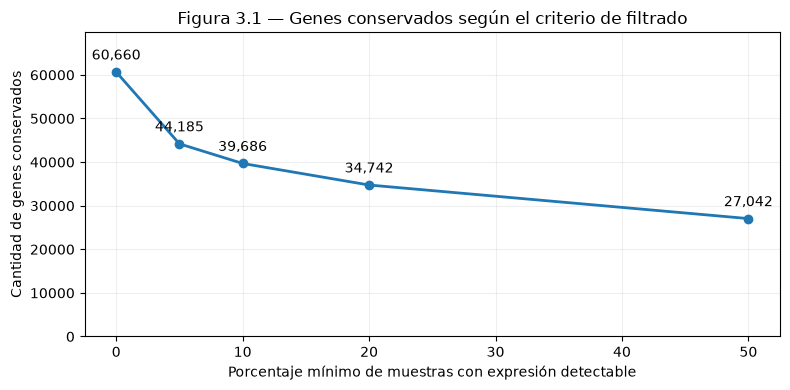

In [13]:

# Proporción de muestras con expresión detectable por gen
proporcion_detectada = (expresion_primaria > 0).mean(axis=1)

# Evaluar diferentes criterios de filtrado
umbrales = [0, 0.05, 0.10, 0.20, 0.50]

resultados_filtrado = []

for umbral in umbrales:
    if umbral == 0:
        n_genes = len(proporcion_detectada)
    else:
        n_genes = (proporcion_detectada >= umbral).sum()

    resultados_filtrado.append({
        "Mínimo de muestras (%)": umbral * 100,
        "Genes conservados": n_genes,
        "Genes eliminados": len(proporcion_detectada) - n_genes,
        "Porcentaje conservado": n_genes / len(proporcion_detectada) * 100
    })

tabla_filtrado = pd.DataFrame(resultados_filtrado)

print("COMPARACIÓN DE CRITERIOS DE FILTRADO")
display(tabla_filtrado.round(2))

# Visualización
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    tabla_filtrado["Mínimo de muestras (%)"],
    tabla_filtrado["Genes conservados"],
    marker="o",
    linewidth=2
)

for x, y in zip(
    tabla_filtrado["Mínimo de muestras (%)"],
    tabla_filtrado["Genes conservados"]
):
    ax.annotate(
        f"{y:,}",
        (x, y),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Figura 3.1 — Genes conservados según el criterio de filtrado")
ax.set_xlabel("Porcentaje mínimo de muestras con expresión detectable")
ax.set_ylabel("Cantidad de genes conservados")
ax.set_ylim(0, len(proporcion_detectada) * 1.15)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()



### Selección del criterio de filtrado

Se decidió utilizar un umbral mínimo del 5% de las muestras para conservar un gen. Con este criterio, el número de genes se reduce de 60,660 a 44,185, eliminando 16,475 genes (27.16%) sin descartar ninguna muestra tumoral.

Se eligió este porcentaje porque permite eliminar una cantidad considerable de genes con expresión poco frecuente, pero mantiene aquellos que podrían estar presentes únicamente en grupos pequeños de pacientes.

El filtrado se mantuvo conservador porque posteriormente se realizará una selección adicional basada en la variabilidad de expresión entre tumores.


In [15]:

# Conservar genes detectados en al menos el 5% de los tumores
umbral_expresion = 0.05

genes_conservados = proporcion_detectada >= umbral_expresion

expresion_filtrada = expresion_primaria.loc[
    genes_conservados
].copy()

print("RESULTADO DEL FILTRADO")
print(f"Genes originales: {expresion_primaria.shape[0]:,}")
print(f"Genes conservados: {expresion_filtrada.shape[0]:,}")
print(f"Genes eliminados: {expresion_primaria.shape[0] - expresion_filtrada.shape[0]:,}")
print(f"Muestras conservadas: {expresion_filtrada.shape[1]:,}")


RESULTADO DEL FILTRADO
Genes originales: 60,660
Genes conservados: 44,185
Genes eliminados: 16,475
Muestras conservadas: 371



### Selección de genes por variabilidad

Después de eliminar los genes con expresión poco frecuente, se analizará la variabilidad de los 44,185 genes restantes.

El objetivo es identificar aquellos cuya expresión cambia más entre pacientes, ya que podrían aportar mayor información para encontrar diferencias moleculares entre tumores.

Para ello, se calculará la varianza de cada gen utilizando sus valores de expresión. Se compararán diferentes porcentajes de selección antes de decidir cuántos genes conservar para PCA y clustering.


ESTADÍSTICAS DE VARIANZA


count    44185.0000
mean         0.3854
std          0.7525
min          0.0000
10%          0.0027
25%          0.0146
50%          0.1281
75%          0.4723
90%          0.9323
95%          1.4742
99%          3.6084
max         15.0753
dtype: float64


GENES CON MAYOR VARIANZA


,id,gene,Varianza
0,ENSG00000160868.15,CYP3A4,15.0753
1,ENSG00000188257.12,PLA2G2A,14.6090
2,ENSG00000132693.12,CRP,14.4885
3,ENSG00000164266.11,SPINK1,14.1780
4,ENSG00000255974.8,CYP2A6,13.7321
5,ENSG00000130649.10,CYP2E1,13.2541
6,ENSG00000172016.16,REG3A,13.0448
7,ENSG00000198074.10,AKR1B10,12.8833
8,ENSG00000211896.7,IGHG1,12.7765
9,ENSG00000173432.12,SAA1,12.0512


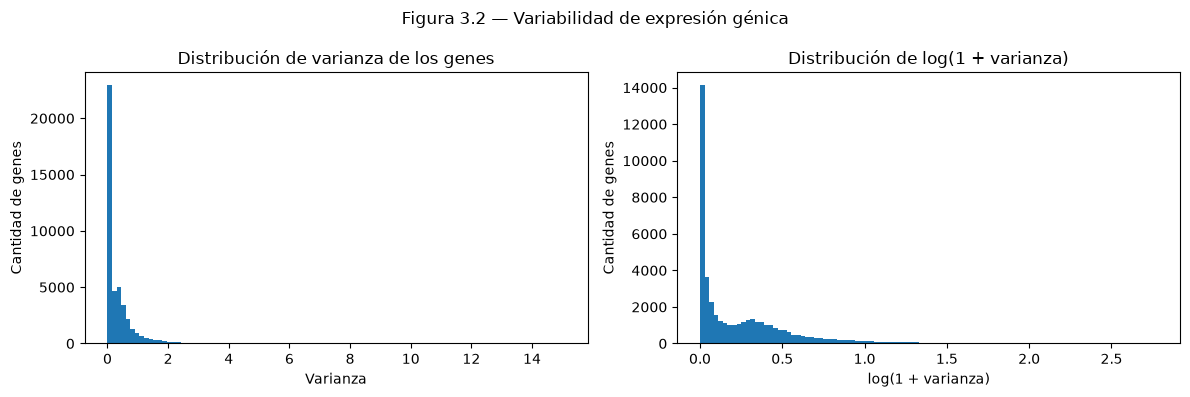

In [16]:

# Calcular varianza de cada gen entre pacientes
varianza_genes = expresion_filtrada.var(axis=1)

print("ESTADÍSTICAS DE VARIANZA")
display(
    varianza_genes.describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(4)
)

print("\nGENES CON MAYOR VARIANZA")
top_genes = varianza_genes.nlargest(10)

# Relacionar identificadores con nombres de genes
top_genes_df = (
    top_genes.rename("Varianza")
    .rename_axis("id")
    .reset_index()
    .merge(mapping[["id", "gene"]], on="id", how="left")
    [["id", "gene", "Varianza"]]
)

display(top_genes_df.round(4))

# Histograma de varianzas
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(varianza_genes, bins=100)
axes[0].set_title("Distribución de varianza de los genes")
axes[0].set_xlabel("Varianza")
axes[0].set_ylabel("Cantidad de genes")

axes[1].hist(np.log1p(varianza_genes), bins=100)
axes[1].set_title("Distribución de log(1 + varianza)")
axes[1].set_xlabel("log(1 + varianza)")
axes[1].set_ylabel("Cantidad de genes")

fig.suptitle("Figura 3.2 — Variabilidad de expresión génica")
plt.tight_layout()
plt.show()


COMPARACIÓN DE CRITERIOS DE VARIABILIDAD


,Porcentaje conservado,Genes conservados,Varianza mínima seleccionada
0,5,2210,1.4743
1,10,4419,0.9324
2,15,6628,0.6975
3,20,8837,0.5650
4,30,13256,0.3984
5,50,22093,0.1281


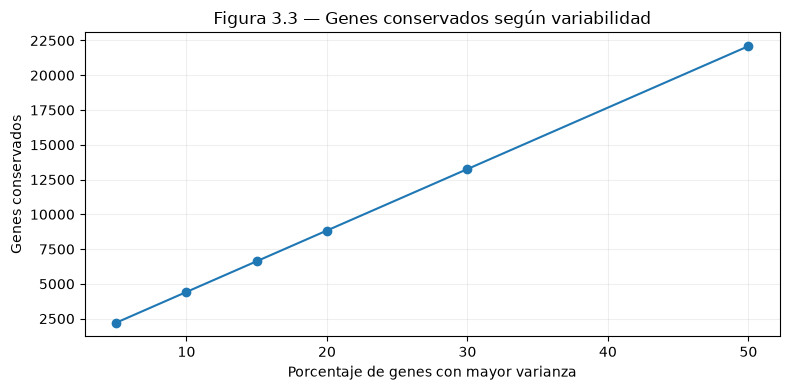

In [17]:

# Evaluar diferentes porcentajes de genes con mayor varianza
porcentajes = [5, 10, 15, 20, 30, 50]

resultados_varianza = []

for porcentaje in porcentajes:
    cantidad = int(np.ceil(
        len(varianza_genes) * porcentaje / 100
    ))

    seleccion = varianza_genes.nlargest(cantidad)

    resultados_varianza.append({
        "Porcentaje conservado": porcentaje,
        "Genes conservados": cantidad,
        "Varianza mínima seleccionada": seleccion.min()
    })

tabla_varianza = pd.DataFrame(resultados_varianza)

print("COMPARACIÓN DE CRITERIOS DE VARIABILIDAD")
display(tabla_varianza.round(4))

# Visualización
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    tabla_varianza["Porcentaje conservado"],
    tabla_varianza["Genes conservados"],
    marker="o"
)

ax.set_title("Figura 3.3 — Genes conservados según variabilidad")
ax.set_xlabel("Porcentaje de genes con mayor varianza")
ax.set_ylabel("Genes conservados")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()



### Interpretación de la variabilidad y selección de genes

La distribución muestra que la mayoría de los genes presenta una varianza baja. La mediana fue de 0.1281, mientras que solamente el 10% de los genes presentó una varianza superior a 0.9323.

Esto indica que gran parte de los genes tiene niveles de expresión relativamente similares entre pacientes, mientras que un grupo más pequeño presenta diferencias considerables.

Al comparar diferentes porcentajes de selección, encontramos que conservar el 10% de los genes con mayor varianza dejaría 4,419 genes, mientras que seleccionar el 20% permitiría conservar 8,837.

Se decidió conservar el 20% de los genes más variables, buscando mantener un equilibrio entre reducir la cantidad de variables y evitar la pérdida de información potencialmente importante. Aunque el 10% permitiría reducir más la dimensionalidad, podría descartar genes útiles para identificar diferencias entre grupos pequeños de tumores.

Con esta decisión se conservarán 8,837 genes y las 371 muestras tumorales. Posteriormente se utilizará PCA para reducir la dimensionalidad, buscando representar la mayor cantidad posible de variabilidad mediante un número menor de componentes principales.

De esta manera, se realiza una selección inicial relativamente conservadora, dejando que PCA permita explorar y resumir la estructura de los datos antes de construir los modelos de clustering.


In [18]:

# Seleccionar el 20% de los genes con mayor varianza
porcentaje_varianza = 0.20

cantidad_genes = int(np.ceil(
    len(varianza_genes) * porcentaje_varianza
))

genes_seleccionados = varianza_genes.nlargest(cantidad_genes).index

# Crear matriz con los genes seleccionados
expresion_seleccionada = expresion_filtrada.loc[
    genes_seleccionados
].copy()

print("RESULTADO DE LA SELECCIÓN")
print(f"Genes originales: {expresion_primaria.shape[0]:,}")
print(f"Después del filtro de expresión: {expresion_filtrada.shape[0]:,}")
print(f"Después del filtro de variabilidad: {expresion_seleccionada.shape[0]:,}")
print(f"Muestras conservadas: {expresion_seleccionada.shape[1]:,}")


RESULTADO DE LA SELECCIÓN
Genes originales: 60,660
Después del filtro de expresión: 44,185
Después del filtro de variabilidad: 8,837
Muestras conservadas: 371



### Estandarización de los datos

Después de seleccionar los 8,837 genes con mayor varianza, se estandarizarán sus valores de expresión antes de aplicar PCA.

Se utilizará StandardScaler para transformar cada gen a una escala con media cero y desviación estándar igual a uno. Esto permite que los genes tengan una influencia comparable en el análisis, evitando que las diferencias de escala determinen los componentes principales.

La estandarización se realizará únicamente sobre los datos de expresión génica, sin incorporar información clínica.


In [19]:

from sklearn.preprocessing import StandardScaler

# Transponer: filas = pacientes, columnas = genes
X = expresion_seleccionada.T.copy()

# Estandarizar cada gen
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convertir a DataFrame para conservar identificadores
X_scaled = pd.DataFrame(
    X_scaled,
    index=X.index,
    columns=X.columns
)

print("MATRIZ PREPARADA PARA PCA")
print(f"Pacientes: {X_scaled.shape[0]:,}")
print(f"Genes: {X_scaled.shape[1]:,}")

# Comprobar estandarización
print("\nVERIFICACIÓN DE ESTANDARIZACIÓN")
print(f"Media máxima absoluta: {X_scaled.mean().abs().max():.6f}")
print(f"Desviación estándar promedio: {X_scaled.std(ddof=0).mean():.6f}")
print(f"Valores faltantes: {X_scaled.isna().sum().sum():,}")


MATRIZ PREPARADA PARA PCA
Pacientes: 371
Genes: 8,837

VERIFICACIÓN DE ESTANDARIZACIÓN
Media máxima absoluta: 0.000001
Desviación estándar promedio: 1.000000
Valores faltantes: 0



### Resultado de la preparación de los datos

Después del primer filtrado se conservaron 44,185 genes, eliminando aquellos con expresión detectable en menos del 5% de los pacientes.

Posteriormente, se seleccionó el 20% de los genes con mayor varianza, reduciendo el conjunto a 8,837 genes. Con ambos filtros se eliminó aproximadamente el 85.4% de las variables originales, conservando las 371 muestras tumorales.

Finalmente, se estandarizaron los valores de expresión utilizando StandardScaler. La verificación mostró que los genes tienen una media prácticamente igual a cero y una desviación estándar de uno, sin presentar valores faltantes.

Con estos resultados, se obtuvo una matriz de 371 pacientes y 8,837 genes, preparada para aplicar PCA y posteriormente los modelos de clustering.



# 4. Reducción de dimensionalidad mediante PCA

El Análisis de Componentes Principales (PCA) permite reducir la cantidad de variables de un conjunto de datos, creando nuevas variables llamadas componentes principales que resumen la variabilidad de la información original.

En este proyecto se utilizará PCA para representar los patrones de expresión de los 8,837 genes mediante un número menor de componentes.

Primero se analizará la varianza explicada por cada componente y la varianza acumulada. Esto permitirá determinar cuántos componentes necesitamos conservar para representar adecuadamente la información antes de aplicar los algoritmos de clustering.


VARIANZA EXPLICADA POR PCA


,Varianza acumulada objetivo,Componentes necesarios
0,60%,20
1,70%,42
2,80%,85
3,90%,171
4,95%,245



PRIMEROS 10 COMPONENTES
PC1: 19.52%
PC2: 9.29%
PC3: 5.84%
PC4: 3.81%
PC5: 3.53%
PC6: 2.80%
PC7: 2.16%
PC8: 2.03%
PC9: 1.41%
PC10: 1.30%


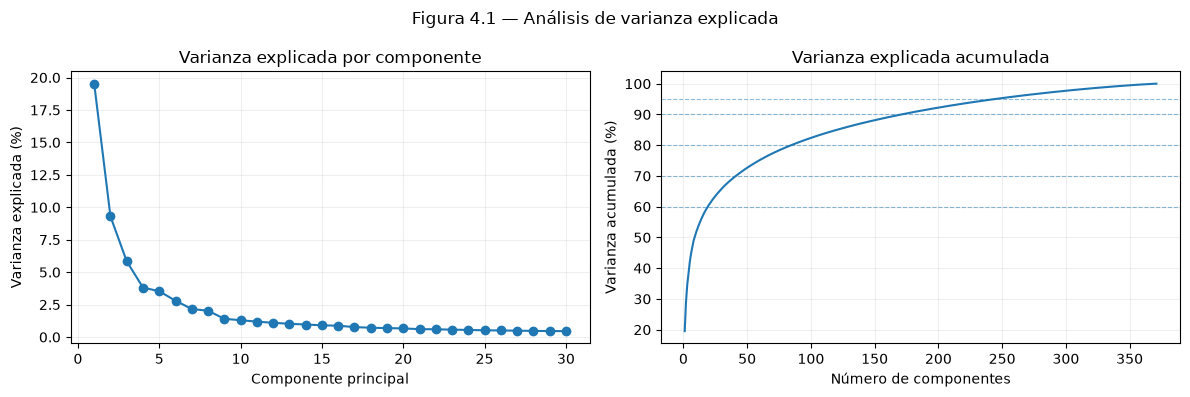

In [20]:

from sklearn.decomposition import PCA

# PCA sobre los datos estandarizados
pca = PCA(svd_solver="full")
X_pca = pca.fit_transform(X_scaled)

# Varianza explicada
varianza_explicada = pca.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)

# Componentes necesarios para distintos porcentajes
umbrales_pca = [0.60, 0.70, 0.80, 0.90, 0.95]

resultados_pca = pd.DataFrame({
    "Varianza acumulada objetivo": [
        f"{u:.0%}" for u in umbrales_pca
    ],
    "Componentes necesarios": [
        np.searchsorted(varianza_acumulada, u) + 1
        for u in umbrales_pca
    ]
})

print("VARIANZA EXPLICADA POR PCA")
display(resultados_pca)

print("\nPRIMEROS 10 COMPONENTES")
for i in range(10):
    print(f"PC{i+1}: {varianza_explicada[i]*100:.2f}%")

# Gráficas
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    range(1, 31),
    varianza_explicada[:30] * 100,
    marker="o"
)
axes[0].set_title("Varianza explicada por componente")
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Varianza explicada (%)")
axes[0].grid(alpha=0.2)

axes[1].plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada * 100
)

for nivel in [60, 70, 80, 90, 95]:
    axes[1].axhline(
        nivel, linestyle="--",
        linewidth=0.8, alpha=0.5
    )

axes[1].set_title("Varianza explicada acumulada")
axes[1].set_xlabel("Número de componentes")
axes[1].set_ylabel("Varianza acumulada (%)")
axes[1].grid(alpha=0.2)

fig.suptitle("Figura 4.1 — Análisis de varianza explicada")
plt.tight_layout()
plt.show()



### Interpretación de la varianza explicada

Los resultados muestran que el primer componente principal explica el 19.52% de la varianza y el segundo el 9.29%, acumulando aproximadamente el 28.81% entre ambos.

En la Figura 4.1 se observa que los primeros componentes explican una proporción considerable de la variabilidad, pero su contribución disminuye rápidamente. A partir de los componentes 4 a 6, la reducción se vuelve más gradual.

Para conservar el 60% de la varianza se necesitan 20 componentes, mientras que el 70% requiere 42 y el 80% requiere 85. Para alcanzar el 90% serían necesarios 171 componentes.

Esto muestra que PCA permite reducir considerablemente la dimensionalidad original. Sin embargo, conservar una mayor proporción de varianza no necesariamente significa obtener mejores agrupaciones, por lo que será importante evaluar la estructura de los datos antes de seleccionar el número definitivo de componentes.


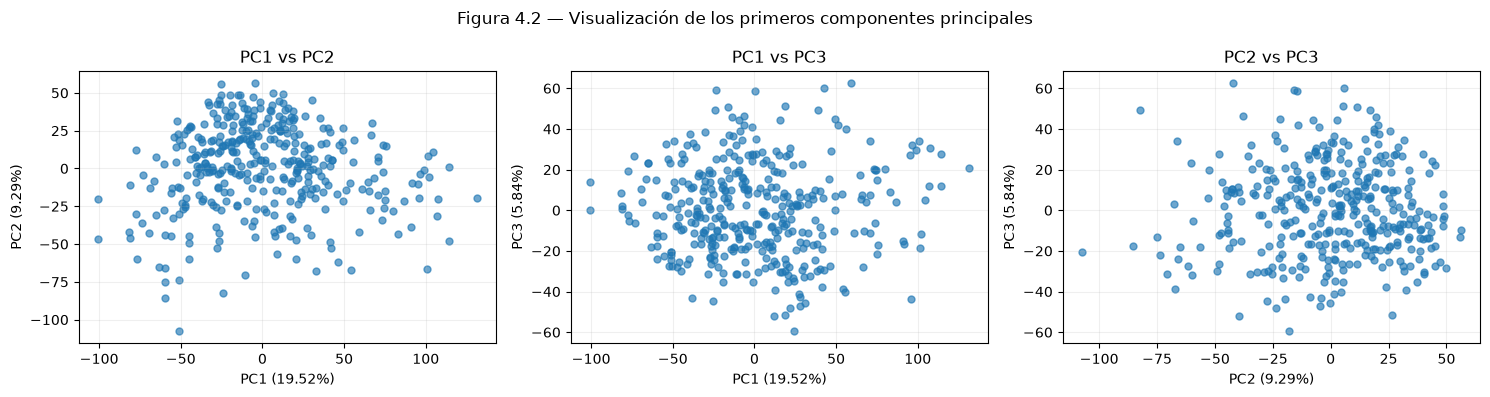

In [21]:

# Crear DataFrame con los primeros componentes
componentes = pd.DataFrame(
    X_pca[:, :3],
    index=X_scaled.index,
    columns=["PC1", "PC2", "PC3"]
)

pares = [
    ("PC1", "PC2"),
    ("PC1", "PC3"),
    ("PC2", "PC3")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (pc_x, pc_y) in zip(axes, pares):
    ax.scatter(
        componentes[pc_x],
        componentes[pc_y],
        alpha=0.65,
        s=25
    )

    indice_x = int(pc_x[2:]) - 1
    indice_y = int(pc_y[2:]) - 1

    ax.set_xlabel(
        f"{pc_x} ({varianza_explicada[indice_x]*100:.2f}%)"
    )
    ax.set_ylabel(
        f"{pc_y} ({varianza_explicada[indice_y]*100:.2f}%)"
    )
    ax.set_title(f"{pc_x} vs {pc_y}")
    ax.grid(alpha=0.2)

fig.suptitle("Figura 4.2 — Visualización de los primeros componentes principales")
plt.tight_layout()
plt.show()



### Selección del número de componentes principales

Las visualizaciones de los primeros tres componentes muestran que los pacientes presentan una distribución continua, sin grupos claramente separados. Sin embargo, estos componentes solamente explican el 34.65% de la varianza total, por lo que podrían existir patrones que no se observan en estas gráficas.

Se decidió conservar los componentes necesarios para explicar al menos el 80% de la varianza acumulada, lo que corresponde a 85 componentes principales.

Se eligió este porcentaje para mantener un enfoque conservador, buscando conservar una parte importante de la variabilidad de los datos sin utilizar las 8,837 variables originales.

Esta selección reduce considerablemente la dimensionalidad y permite trabajar con una representación más compacta de los tumores. Sin embargo, el 80% no garantiza obtener mejores clusters, por lo que será necesario evaluar los resultados de los algoritmos de agrupamiento.


In [22]:

# Seleccionar componentes que explican al menos el 80% de la varianza
n_componentes = np.searchsorted(varianza_acumulada, 0.80) + 1

# Crear matriz reducida para clustering
X_reducido = pd.DataFrame(
    X_pca[:, :n_componentes],
    index=X_scaled.index,
    columns=[f"PC{i+1}" for i in range(n_componentes)]
)

print("MATRIZ FINAL PARA CLUSTERING")
print(f"Pacientes: {X_reducido.shape[0]:,}")
print(f"Componentes principales: {X_reducido.shape[1]}")
print(f"Varianza acumulada: {varianza_acumulada[n_componentes-1]*100:.2f}%")

display(X_reducido.iloc[:5, :5])


MATRIZ FINAL PARA CLUSTERING
Pacientes: 371
Componentes principales: 85
Varianza acumulada: 80.09%


,PC1,PC2,PC3,PC4,PC5
TCGA-5R-AA1C-01A,-9.656118,39.666592,-13.950418,51.246502,6.372915
TCGA-ED-A66Y-01A,42.457417,5.281667,-29.191490,-31.555204,-35.143456
TCGA-DD-AAEI-01A,-40.263405,8.868924,4.607154,-5.255431,16.919027
TCGA-ED-A8O5-01A,19.110924,11.263445,-26.231066,-12.389444,-32.684662
TCGA-DD-AACH-01A,71.036880,7.859836,-11.057693,-0.874542,14.511917



### 5.1 K-Means Clustering

K-Means es un algoritmo de aprendizaje no supervisado que agrupa observaciones según su similitud. Para ello, asigna cada observación al centroide más cercano y actualiza los centroides hasta que las agrupaciones se estabilizan.

En este proyecto se utilizarán los 85 componentes principales seleccionados previamente para agrupar las 371 muestras tumorales.

Como no conocemos el número de subgrupos moleculares presentes, se probarán diferentes valores de K. Los resultados se evaluarán mediante la inercia, el Silhouette Score y el tamaño de los clusters.

También se utilizarán múltiples inicializaciones para reducir la dependencia del algoritmo respecto a los centroides iniciales.


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Evaluar diferentes cantidades de clusters
valores_k = range(2, 11)

resultados_kmeans = []
modelos_kmeans = {}

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        n_init=30,
        random_state=10
    )

    etiquetas = modelo.fit_predict(X_reducido)

    modelos_kmeans[k] = modelo

    # Tamaño de los clusters
    tamaños = np.bincount(etiquetas, minlength=k)

    resultados_kmeans.append({
        "K": k,
        "Inercia": modelo.inertia_,
        "Silhouette Score": silhouette_score(
            X_reducido, etiquetas
        ),
        "Cluster mínimo": tamaños.min(),
        "Cluster máximo": tamaños.max()
    })

tabla_kmeans = pd.DataFrame(resultados_kmeans)

print("COMPARACIÓN DE MODELOS K-MEANS")
display(tabla_kmeans.round(4))


COMPARACIÓN DE MODELOS K-MEANS


,K,Inercia,Silhouette Score,Cluster mínimo,Cluster máximo
0,2,2210219.500,0.1505,153,218
1,3,2029805.000,0.0982,86,168
2,4,1911859.250,0.0931,43,152
3,5,1826382.375,0.0833,43,112
4,6,1762372.250,0.0764,42,97
5,7,1707168.125,0.0758,40,69
6,8,1664967.000,0.0723,30,65
7,9,1622670.375,0.0769,10,66
8,10,1592208.500,0.0877,6,92


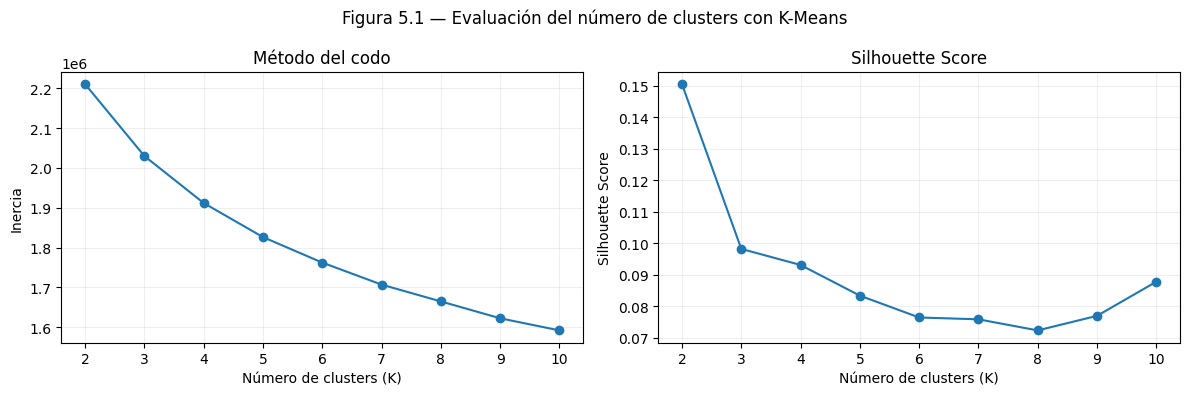

In [25]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Método del codo
axes[0].plot(
    tabla_kmeans["K"],
    tabla_kmeans["Inercia"],
    marker="o"
)

axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clusters (K)")
axes[0].set_ylabel("Inercia")
axes[0].grid(alpha=0.2)

# Silhouette Score
axes[1].plot(
    tabla_kmeans["K"],
    tabla_kmeans["Silhouette Score"],
    marker="o"
)

axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Número de clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.2)

fig.suptitle("Figura 5.1 — Evaluación del número de clusters con K-Means")

plt.tight_layout()
plt.show()



### Evaluación del número de clusters

Se probaron valores de K entre 2 y 10, comparando la inercia, el Silhouette Score y el tamaño de los clusters.

La inercia disminuyó conforme aumentó el número de grupos, aunque no se identificó un punto de codo claramente definido. Esto dificulta seleccionar un valor de K utilizando únicamente esta métrica.

El mayor Silhouette Score se obtuvo con K=2, alcanzando 0.1505. Para K=3 disminuyó a 0.0982 y los valores posteriores se mantuvieron por debajo de 0.10.

Con K=2 se obtuvieron grupos de 153 y 218 pacientes, mientras que al aumentar K comenzaron a aparecer grupos más pequeños.

Estos resultados sugieren que K=2 es la alternativa más favorable entre las evaluadas. Sin embargo, el Silhouette Score es relativamente bajo, lo que indica que los grupos no presentan una separación clara.

Por esta razón, se utilizará K=2 como candidato inicial para K-Means, pero todavía no se considerará una agrupación definitiva. Será necesario comparar sus resultados con Hierarchical Clustering y revisar si los grupos presentan diferencias moleculares relevantes.


DISTRIBUCIÓN DE CLUSTERS


,Cluster,Pacientes
0,0,153
1,1,218


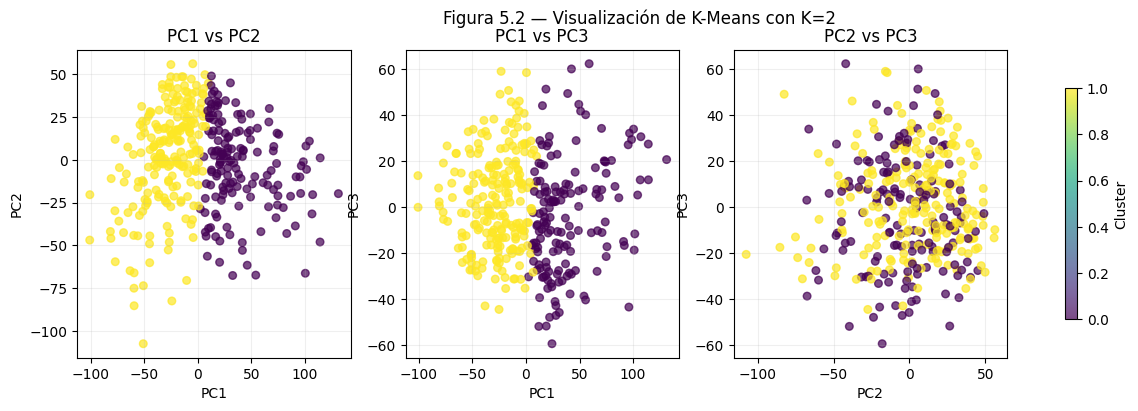

In [26]:

# Recuperar modelo K-Means con K=2
kmeans_2 = modelos_kmeans[2]

# Etiquetas de los clusters
labels_kmeans = kmeans_2.labels_

# Tamaño de cada cluster
print("DISTRIBUCIÓN DE CLUSTERS")
display(
    pd.Series(labels_kmeans)
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Pacientes")
)

# Visualizar clusters en los primeros componentes principales
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

pares = [(0, 1), (0, 2), (1, 2)]

for ax, (i, j) in zip(axes, pares):
    scatter = ax.scatter(
        X_pca[:, i],
        X_pca[:, j],
        c=labels_kmeans,
        cmap="viridis",
        alpha=0.7,
        s=30
    )

    ax.set_xlabel(f"PC{i+1}")
    ax.set_ylabel(f"PC{j+1}")
    ax.set_title(f"PC{i+1} vs PC{j+1}")
    ax.grid(alpha=0.2)

fig.suptitle("Figura 5.2 — Visualización de K-Means con K=2")
fig.colorbar(scatter, ax=axes, label="Cluster", shrink=0.75)

plt.show()



### Interpretación de los clusters de K-Means

La Figura 5.2 muestra la distribución de los dos clusters obtenidos mediante K-Means sobre los primeros componentes principales.

En las gráficas PC1 vs. PC2 y PC1 vs. PC3 se observa una separación relativamente clara entre los grupos, principalmente a lo largo del primer componente principal. Uno de los clusters se concentra en valores negativos de PC1 y el otro en valores positivos.

Sin embargo, en la gráfica PC2 vs. PC3 los grupos aparecen considerablemente mezclados. Esto sugiere que la separación identificada por K-Means está relacionada principalmente con la variabilidad representada por PC1.

Aunque las visualizaciones muestran diferencias entre los grupos, el Silhouette Score de 0.1505 indica que la separación general es débil al considerar los 85 componentes utilizados por el modelo.

Por lo tanto, K-Means permite identificar dos agrupaciones iniciales, pero todavía no existe evidencia suficiente para considerarlas subtipos moleculares. Será necesario comparar estos resultados con Hierarchical Clustering y posteriormente analizar los genes que diferencian a los grupos.



### 5.2 Hierarchical Clustering

Hierarchical Clustering es un método de aprendizaje no supervisado que agrupa observaciones según su similitud. A diferencia de K-Means, no necesita establecer inicialmente una cantidad fija de clusters.

El algoritmo comienza considerando cada muestra como un grupo independiente y posteriormente une los grupos más similares. El resultado se representa mediante un dendrograma, que permite visualizar cómo se relacionan las observaciones.


### Comparación de métodos de enlace

Para evaluar cómo influye el método de enlace en los resultados del clustering jerárquico, se compararán Complete y Ward utilizando distancia euclidiana.

Complete utiliza la mayor distancia entre las observaciones de dos grupos para decidir cómo unirlos, mientras que Ward busca minimizar el aumento de la variabilidad interna de los clusters.

Primero se compararán visualmente sus dendrogramas. Después se evaluarán diferentes cantidades de clusters mediante Silhouette Score y el tamaño de los grupos.

La selección del método se basará en estas métricas y no solamente en la apariencia del dendrograma.


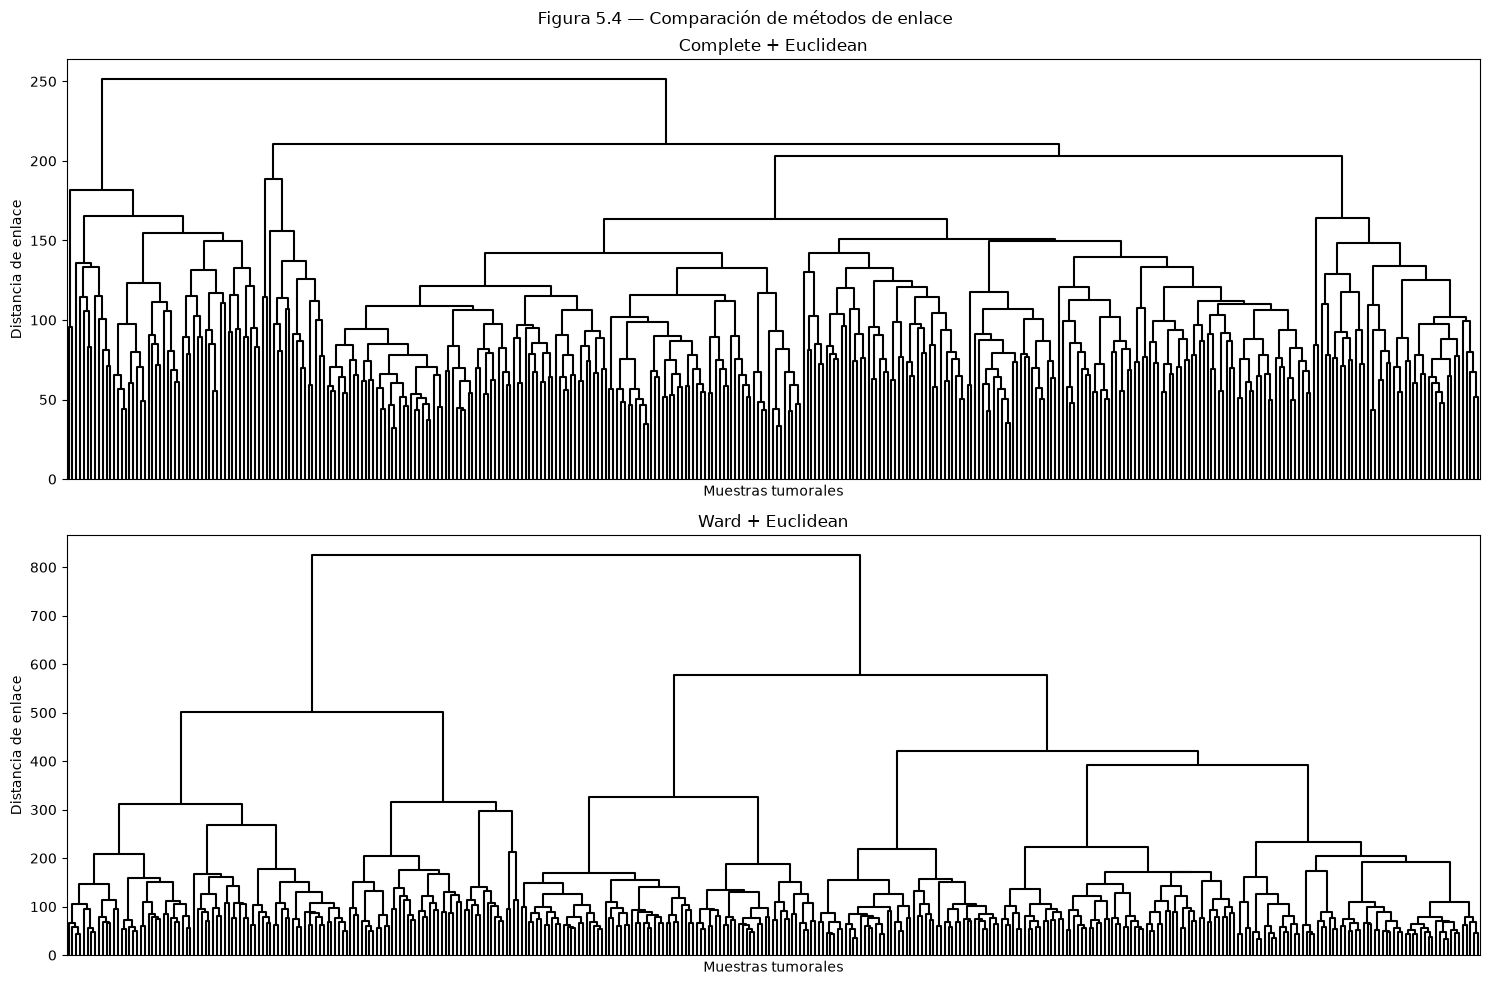

In [31]:

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Calcular ambos métodos sobre los mismos 85 componentes
metodos = {
    "Complete": linkage(
        X_reducido.to_numpy(),
        method="complete",
        metric="euclidean"
    ),
    "Ward": linkage(
        X_reducido.to_numpy(),
        method="ward",
        metric="euclidean"
    )
}

# Mostrar ambos dendrogramas
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

for ax, (nombre, Z) in zip(axes, metodos.items()):
    dendrogram(
        Z,
        ax=ax,
        no_labels=True,
        color_threshold=0,
        above_threshold_color="black"
    )

    ax.set_title(f"{nombre} + Euclidean")
    ax.set_xlabel("Muestras tumorales")
    ax.set_ylabel("Distancia de enlace")

fig.suptitle("Figura 5.4 — Comparación de métodos de enlace")

plt.tight_layout()
plt.show()


In [32]:

resultados = []

for nombre, Z in metodos.items():
    for k in range(2, 7):

        etiquetas = fcluster(
            Z,
            t=k,
            criterion="maxclust"
        )

        tamaños = pd.Series(etiquetas).value_counts()

        resultados.append({
            "Método": nombre,
            "K": k,
            "Silhouette Score": silhouette_score(
                X_reducido, etiquetas
            ),
            "Cluster mínimo": tamaños.min(),
            "Cluster máximo": tamaños.max()
        })

comparacion_jerarquica = pd.DataFrame(resultados)

print("COMPARACIÓN DE MÉTODOS JERÁRQUICOS")
display(
    comparacion_jerarquica
    .sort_values("Silhouette Score", ascending=False)
    .round(4)
)

# Seleccionar automáticamente la configuración con mejor Silhouette
# entre las que tienen al menos 10 pacientes en cada cluster
candidatos = comparacion_jerarquica[
    comparacion_jerarquica["Cluster mínimo"] >= 10
]

mejor = candidatos.sort_values(
    "Silhouette Score",
    ascending=False
).iloc[0]

mejor_metodo = mejor["Método"]
mejor_k = int(mejor["K"])

Z_mejor = metodos[mejor_metodo]

labels_jerarquico = fcluster(
    Z_mejor,
    t=mejor_k,
    criterion="maxclust"
)

print("\nMEJOR CONFIGURACIÓN SEGÚN SILHOUETTE")
print(f"Método: {mejor_metodo}")
print(f"Número de clusters: {mejor_k}")
print(f"Silhouette Score: {mejor['Silhouette Score']:.4f}")
print(f"Cluster mínimo: {mejor['Cluster mínimo']}")
print(f"Cluster máximo: {mejor['Cluster máximo']}")


COMPARACIÓN DE MÉTODOS JERÁRQUICOS


,Método,K,Silhouette Score,Cluster mínimo,Cluster máximo
0,Complete,2,0.2089,51,320
1,Complete,3,0.1656,17,303
5,Ward,2,0.1478,119,252
2,Complete,4,0.1156,17,259
4,Complete,6,0.1123,2,259
3,Complete,5,0.1120,2,259
7,Ward,4,0.0755,45,174
6,Ward,3,0.0727,78,174
8,Ward,5,0.0713,45,126
9,Ward,6,0.0635,45,78



MEJOR CONFIGURACIÓN SEGÚN SILHOUETTE
Método: Complete
Número de clusters: 2
Silhouette Score: 0.2089
Cluster mínimo: 51
Cluster máximo: 320



### Comparación de métodos de clustering jerárquico

Se compararon los métodos Complete y Ward utilizando distancia euclidiana y los 85 componentes principales seleccionados previamente.

Los dendrogramas muestran diferencias en la manera en que se agrupan los pacientes. Ward presenta una estructura visual con dos ramas principales y grupos relativamente equilibrados, mientras que Complete genera una división más desigual.

Al evaluar Silhouette Score, Complete obtuvo el mejor resultado con K=2 y una puntuación de 0.2089, formando grupos de 51 y 320 pacientes. Ward obtuvo 0.1478 con K=2, formando grupos de 119 y 252 pacientes.

Aunque Complete presenta una mayor separación según Silhouette, Ward produce grupos más equilibrados. Por esta razón, no se seleccionará todavía un método definitivo.

Se comparará la coincidencia de ambos modelos con K-Means para determinar si las agrupaciones identificadas son consistentes entre diferentes algoritmos.


In [33]:

from sklearn.metrics import adjusted_rand_score

# Obtener agrupaciones de cada modelo con K=2
labels_complete = fcluster(
    metodos["Complete"], t=2, criterion="maxclust"
)

labels_ward = fcluster(
    metodos["Ward"], t=2, criterion="maxclust"
)

# Comparar coincidencia entre modelos
comparaciones = {
    "K-Means vs Complete": adjusted_rand_score(
        labels_kmeans, labels_complete
    ),
    "K-Means vs Ward": adjusted_rand_score(
        labels_kmeans, labels_ward
    ),
    "Complete vs Ward": adjusted_rand_score(
        labels_complete, labels_ward
    )
}

print("COINCIDENCIA ENTRE MODELOS (ARI)")

for nombre, ari in comparaciones.items():
    print(f"{nombre}: {ari:.4f}")


COINCIDENCIA ENTRE MODELOS (ARI)
K-Means vs Complete: 0.1885
K-Means vs Ward: 0.4543
Complete vs Ward: 0.3571



### Comparación de coincidencia entre modelos

Para evaluar la similitud entre las agrupaciones se utilizó el Adjusted Rand Index (ARI), que permite comparar cómo se asignan los pacientes a los clusters sin depender de las etiquetas numéricas de cada grupo.

La mayor coincidencia se obtuvo entre K-Means y Ward, con un ARI de 0.4543. En cambio, K-Means y Complete obtuvieron 0.1885, mientras que Complete y Ward alcanzaron 0.3571.

Estos resultados muestran que Ward identifica una estructura más parecida a la encontrada por K-Means. Sin embargo, Complete obtuvo un Silhouette Score superior, lo que indica una mejor separación de sus grupos según esta métrica.

Por esta razón, se decidió conservar ambos métodos jerárquicos para los análisis posteriores. La selección definitiva dependerá de las diferencias moleculares y clínicas encontradas entre los grupos, así como de la consistencia de los resultados.



# 6. Interpretación molecular de los clusters

Después de aplicar K-Means y Hierarchical Clustering, se identificaron diferentes agrupaciones de pacientes. Aunque Complete obtuvo un mejor Silhouette Score, Ward presentó grupos más equilibrados y una mayor coincidencia con K-Means.

Para comprender mejor estas diferencias, se analizarán los genes cuya expresión cambia más entre los clusters de cada modelo.

El objetivo es identificar patrones moleculares que permitan caracterizar las agrupaciones. Se utilizarán los valores originales de expresión transformados mediante log2(TPM+1), antes de la estandarización, para comparar los niveles de expresión entre grupos.

Se conservarán ambos métodos como candidatos hasta evaluar sus resultados moleculares y clínicos.


In [34]:

# Matriz de expresión original de los genes seleccionados
# Filas: pacientes, columnas: genes
X_genes = expresion_seleccionada.T.loc[X_reducido.index].copy()

# Etiquetas de ambos modelos
modelos_moleculares = {
    "Complete": labels_complete,
    "Ward": labels_ward
}

def comparar_genes(X, etiquetas, mapping):
    etiquetas = pd.Series(etiquetas, index=X.index)

    # Expresión promedio por cluster
    medias = X.groupby(etiquetas).mean()

    # Diferencia absoluta de expresión entre ambos grupos
    diferencia = (medias.iloc[0] - medias.iloc[1]).abs()

    # Construir tabla de resultados
    resultados = pd.DataFrame({
        "id": diferencia.index,
        "Media cluster 1": medias.iloc[0].values,
        "Media cluster 2": medias.iloc[1].values,
        "Diferencia absoluta": diferencia.values
    })

    # Incorporar nombres de genes
    resultados = resultados.merge(
        mapping[["id", "gene"]],
        on="id",
        how="left"
    )

    return resultados.sort_values(
        "Diferencia absoluta",
        ascending=False
    ).reset_index(drop=True)

# Analizar ambos modelos
genes_complete = comparar_genes(
    X_genes, labels_complete, mapping
)

genes_ward = comparar_genes(
    X_genes, labels_ward, mapping
)

print("COMPLETE — 10 GENES CON MAYOR DIFERENCIA")
display(genes_complete.head(10).round(4))

print("\nWARD — 10 GENES CON MAYOR DIFERENCIA")
display(genes_ward.head(10).round(4))


COMPLETE — 10 GENES CON MAYOR DIFERENCIA


,id,Media cluster 1,Media cluster 2,Diferencia absoluta,gene
0,ENSG00000171345.13,5.6804,1.7460,3.9344,KRT19
1,ENSG00000166145.14,6.1239,2.2100,3.9139,SPINT1
2,ENSG00000119888.11,6.0526,2.3117,3.7410,EPCAM
3,ENSG00000117601.14,8.0025,11.5940,3.5914,SERPINC1
4,ENSG00000137673.9,5.1975,1.6725,3.5250,MMP7
5,ENSG00000158104.11,5.3568,8.8723,3.5156,HPD
6,ENSG00000158874.11,11.2115,14.5448,3.3333,APOA2
7,ENSG00000145192.13,7.9829,11.2653,3.2824,AHSG
8,ENSG00000139329.5,6.5681,3.4056,3.1625,LUM
9,ENSG00000118785.14,9.4368,6.2800,3.1568,SPP1



WARD — 10 GENES CON MAYOR DIFERENCIA


,id,Media cluster 1,Media cluster 2,Diferencia absoluta,gene
0,ENSG00000158104.11,5.6924,9.6625,3.9701,HPD
1,ENSG00000255974.8,4.0640,8.0104,3.9464,CYP2A6
2,ENSG00000180432.6,3.1490,6.9890,3.8400,CYP8B1
3,ENSG00000198650.11,3.9022,7.6830,3.7808,TAT
4,ENSG00000100652.5,3.3323,7.0251,3.6928,SLC10A1
5,ENSG00000160868.15,3.5194,6.9887,3.4693,CYP3A4
6,ENSG00000081051.8,6.4195,2.9889,3.4306,AFP
7,ENSG00000149124.11,2.1208,5.4998,3.3789,GLYAT
8,ENSG00000119888.11,5.0338,1.7834,3.2504,EPCAM
9,ENSG00000211896.7,8.4920,5.2608,3.2312,IGHG1


In [35]:

for n in [30, 50]:
    top_complete = set(genes_complete.head(n)["id"])
    top_ward = set(genes_ward.head(n)["id"])

    compartidos = top_complete & top_ward

    print(f"\nCOMPARACIÓN DE LOS {n} GENES PRINCIPALES")
    print(f"Genes compartidos: {len(compartidos)}")
    print(f"Porcentaje de coincidencia: {len(compartidos) / n * 100:.2f}%")

# Mostrar genes compartidos entre los primeros 30
top30_complete = set(genes_complete.head(30)["id"])
top30_ward = set(genes_ward.head(30)["id"])

genes_comunes = top30_complete & top30_ward

tabla_comunes = (
    mapping[mapping["id"].isin(genes_comunes)][["id", "gene"]]
    .sort_values("gene")
)

print("\nGENES COMPARTIDOS ENTRE LOS TOP 30")
display(tabla_comunes)



COMPARACIÓN DE LOS 30 GENES PRINCIPALES
Genes compartidos: 10
Porcentaje de coincidencia: 33.33%

COMPARACIÓN DE LOS 50 GENES PRINCIPALES
Genes compartidos: 21
Porcentaje de coincidencia: 42.00%

GENES COMPARTIDOS ENTRE LOS TOP 30


,id,gene
42920,ENSG00000103569.10,AQP9
47975,ENSG00000275152.5,CCL16
52732,ENSG00000255974.8,CYP2A6
6273,ENSG00000119888.11,EPCAM
37800,ENSG00000158104.11,HPD
46159,ENSG00000261701.7,HPR
48249,ENSG00000171345.13,KRT19
3976,ENSG00000117601.14,SERPINC1
42494,ENSG00000166145.14,SPINT1
46134,ENSG00000198650.11,TAT



### Comparación de genes entre Complete y Ward

Se calcularon las diferencias de expresión promedio entre los dos clusters de cada modelo, utilizando los 8,837 genes seleccionados previamente.

En Complete, los genes con mayores diferencias fueron KRT19, SPINT1 y EPCAM. En Ward destacaron HPD, CYP2A6 y CYP8B1.

Al comparar los 30 genes principales de ambos métodos, encontramos 10 genes compartidos, equivalentes al 33.33%. Al ampliar la comparación a 50 genes, la coincidencia aumentó a 21 genes (42%).

Estos resultados muestran que ambos modelos identifican algunas diferencias moleculares similares, aunque también presentan diferencias importantes en los genes que caracterizan a sus grupos.

Por ahora no se puede determinar qué modelo representa mejor los posibles subgrupos moleculares. Para continuar con la evaluación, se visualizará la expresión de los genes principales mediante mapas de calor, buscando identificar patrones consistentes entre pacientes.



### Visualización de patrones moleculares mediante mapas de calor

Para visualizar las diferencias de expresión entre los clusters, se generarán mapas de calor con los 30 genes que presentan mayores diferencias de expresión promedio en cada modelo.

Cada columna representará un paciente y cada fila un gen. Los pacientes se organizarán según el cluster asignado.

Para facilitar la comparación entre genes, sus valores de expresión se representarán mediante puntajes Z. Los valores positivos indicarán una expresión superior al promedio de ese gen y los negativos una expresión inferior.

Esta visualización permitirá comprobar si las diferencias encontradas en los promedios también se observan de manera consistente entre los pacientes de cada grupo.


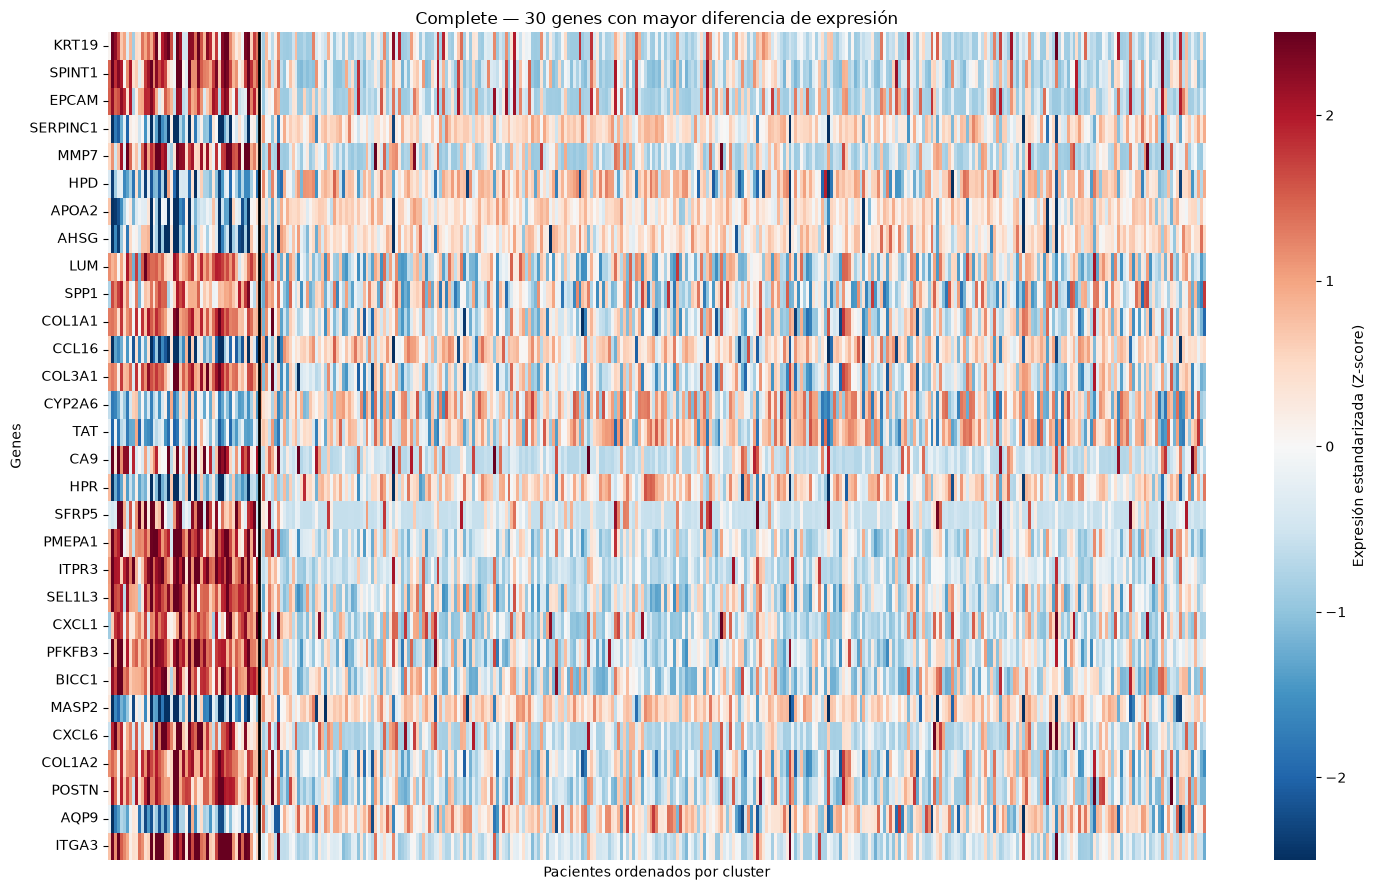

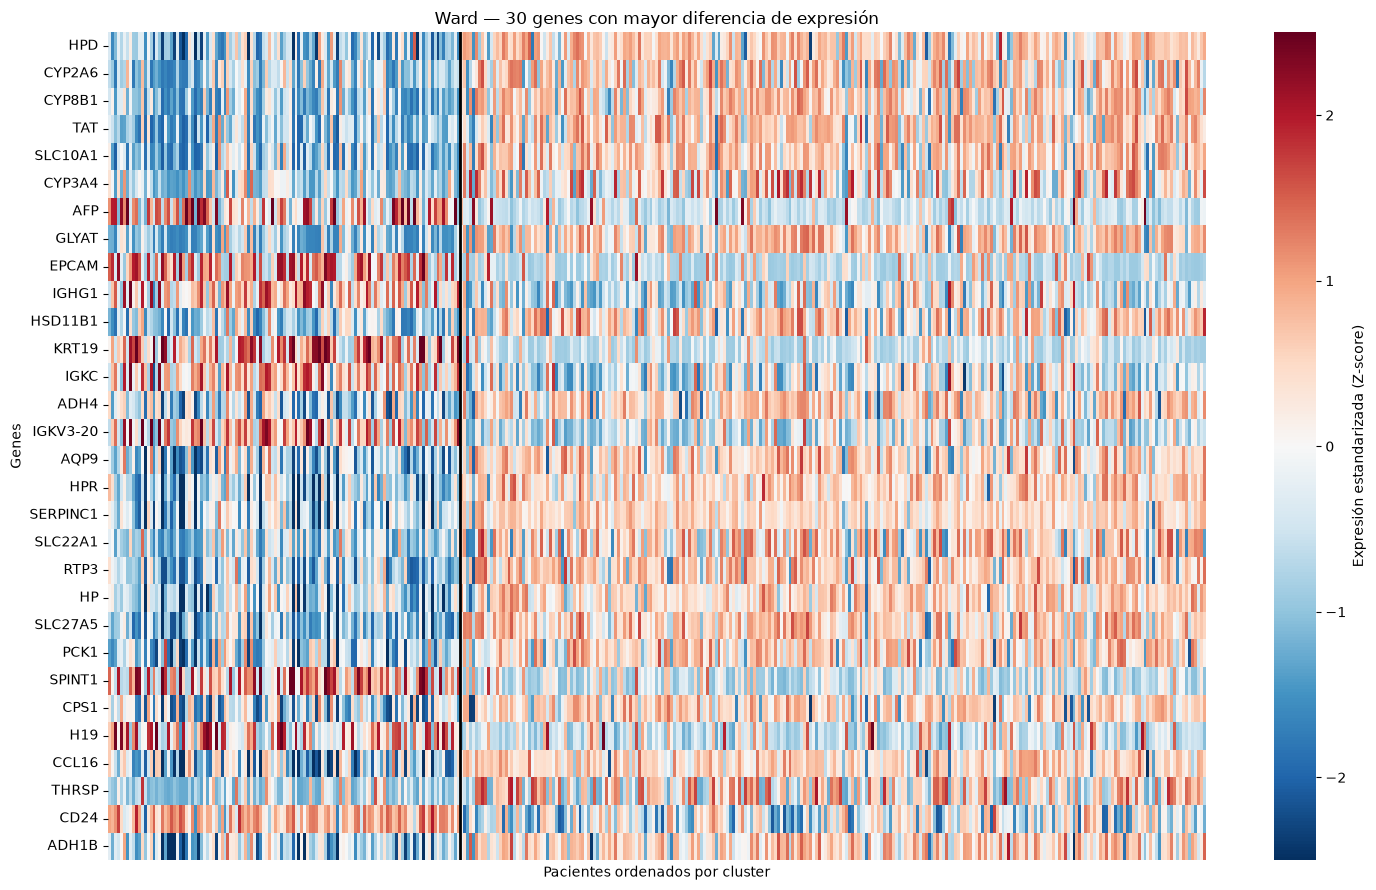

In [36]:

import seaborn as sns

def visualizar_heatmap_genes(X, etiquetas, tabla_genes, nombre, n=30):

    # Seleccionar genes con mayores diferencias
    genes = tabla_genes.head(n)["id"].tolist()

    # Mantener los valores originales de expresión
    datos = X[genes].copy()

    # Estandarizar cada gen únicamente para visualizarlo
    medias = datos.mean(axis=0)
    desviaciones = datos.std(axis=0, ddof=0)

    datos_z = (datos - medias) / desviaciones.replace(0, 1)

    # Ordenar pacientes por cluster
    grupos = pd.Series(etiquetas, index=X.index)
    orden = grupos.sort_values().index

    matriz = datos_z.loc[orden].T

    # Sustituir IDs de Ensembl por nombres de genes
    nombres = mapping.set_index("id")["gene"].to_dict()

    matriz.index = [
        nombres.get(gen, gen) for gen in matriz.index
    ]

    # Dibujar heatmap
    fig, ax = plt.subplots(figsize=(15, 9))

    sns.heatmap(
        matriz,
        cmap="RdBu_r",
        center=0,
        vmin=-2.5,
        vmax=2.5,
        xticklabels=False,
        yticklabels=True,
        cbar_kws={"label": "Expresión estandarizada (Z-score)"},
        ax=ax
    )

    # Marcar separación entre clusters
    tamaños = grupos.value_counts().sort_index()

    separacion = tamaños.iloc[0]
    ax.axvline(separacion, color="black", linewidth=2)

    ax.set_title(
        f"{nombre} — {n} genes con mayor diferencia de expresión"
    )
    ax.set_xlabel("Pacientes ordenados por cluster")
    ax.set_ylabel("Genes")

    plt.tight_layout()
    plt.show()


# Complete
visualizar_heatmap_genes(
    X_genes,
    labels_complete,
    genes_complete,
    "Complete",
    n=30
)

# Ward
visualizar_heatmap_genes(
    X_genes,
    labels_ward,
    genes_ward,
    "Ward",
    n=30
)



### Interpretación de los mapas de calor

Los mapas de calor muestran diferencias en los patrones de expresión génica identificados por Complete y Ward.

En Complete se observa un grupo de 51 pacientes con mayor expresión relativa de genes como KRT19, EPCAM y SPINT1, mientras que genes como HPD y APOA2 presentan una expresión menor. El resto de los pacientes muestra una distribución más variable.

En Ward, los 119 pacientes del primer cluster presentan mayor expresión de EPCAM, KRT19 y SPINT1, junto con menor expresión de HPD, CYP2A6 y CYP8B1. El segundo cluster, formado por 252 pacientes, presenta principalmente el patrón contrario.

En general, ambos métodos identifican diferencias moleculares, aunque Complete concentra las diferencias más marcadas en un grupo pequeño, mientras que Ward presenta una división más equilibrada de los pacientes.

Estas diferencias permiten caracterizar inicialmente las agrupaciones mediante sus patrones de expresión génica.



# 7. Comparación de características clínicas entre clusters

Después de identificar diferencias en la expresión génica, se analizarán las características clínicas de los pacientes de cada grupo.

Se compararán la edad, el sexo, el estadio patológico y el estado vital para explorar si las diferencias moleculares también se relacionan con características de la enfermedad.

Para facilitar la comparación, los subestadios patológicos se agruparán en las categorías generales I, II, III y IV.

Este análisis permitirá describir las características de los clusters obtenidos mediante Complete y Ward.


In [37]:

# Organizar información clínica por muestra
clinica_comparacion = (
    datos_clinicos
    .drop_duplicates(subset="Muestra")
    .set_index("Muestra")
    .reindex(X_reducido.index)
    .copy()
)

# Agrupar subestadios en categorías generales
clinica_comparacion["Estadio general"] = (
    clinica_comparacion["Estadio"]
    .astype("string")
    .str.extract(r"Stage\s+(IV|III|II|I)(?:[ABC])?\b", expand=False)
)

# Agregar etiquetas de ambos modelos
clinica_comparacion["Complete"] = labels_complete
clinica_comparacion["Ward"] = labels_ward

print("PACIENTES POR MODELO")
for metodo in ["Complete", "Ward"]:
    print(f"\n{metodo}")
    display(
        clinica_comparacion[metodo]
        .value_counts()
        .sort_index()
    )

print("\nCORRESPONDENCIA DE DATOS CLÍNICOS")
display(
    clinica_comparacion[
        ["Edad", "Sexo", "Estadio general", "Estado vital"]
    ].isna().sum().to_frame("Valores faltantes")
)

# Comparación descriptiva
for metodo in ["Complete", "Ward"]:

    print(f"\n{'='*40}")
    print(f"MODELO: {metodo}")
    print(f"{'='*40}")

    print("\nEDAD POR CLUSTER")
    display(
        clinica_comparacion.groupby(metodo)["Edad"]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )

    for variable in ["Sexo", "Estadio general", "Estado vital"]:

        print(f"\n{variable.upper()} POR CLUSTER")

        tabla = pd.crosstab(
            clinica_comparacion[metodo],
            clinica_comparacion[variable],
            dropna=False
        )

        display(tabla)

        print("Porcentajes por cluster:")
        display(
            (tabla.div(tabla.sum(axis=1), axis=0) * 100)
            .round(1)
        )


PACIENTES POR MODELO

Complete


Complete
1     51
2    320
Name: count, dtype: int64


Ward


Ward
1    119
2    252
Name: count, dtype: int64


CORRESPONDENCIA DE DATOS CLÍNICOS


,Valores faltantes
Edad,1
Sexo,0
Estadio general,24
Estado vital,1


... (24 outputs left out)


ESTADO VITAL POR CLUSTER


Estado vital,Alive,Dead,NaN
Ward,,,
1,73,46,0
2,167,84,1


Porcentajes por cluster:


Estado vital,Alive,Dead,NaN
Ward,,,
1,61.3,38.7,0.0
2,66.3,33.3,0.4



### Interpretación de las características clínicas

La comparación clínica muestra algunas diferencias entre los clusters identificados por Complete y Ward.

En ambos modelos, los pacientes del primer cluster presentan una edad promedio ligeramente menor y una proporción más alta de mujeres.

También se encontraron diferencias en el estadio patológico. En Complete, el 35.3% de los pacientes del primer cluster pertenece al estadio III, frente al 20.9% del segundo. En Ward, estos porcentajes fueron de 31.9% y 18.7%, respectivamente.

Respecto al estado vital, el primer cluster de ambos modelos presenta una mayor proporción de pacientes fallecidos. Sin embargo, esta comparación no considera el tiempo de seguimiento de cada paciente.

En general, los resultados sugieren que las agrupaciones moleculares podrían estar relacionadas con algunas características clínicas, especialmente el sexo y el estadio patológico. Para determinar si estas diferencias son estadísticamente significativas, será necesario realizar pruebas adicionales.



### Evaluación estadística de las diferencias clínicas

Para complementar la comparación descriptiva, se realizarán pruebas estadísticas entre los dos clusters de cada modelo.

Se utilizará Mann-Whitney U para comparar las edades, ya que permite evaluar diferencias entre dos grupos independientes sin asumir una distribución normal.

Para el sexo y el estadio patológico se utilizará la prueba Chi-cuadrado, que permite evaluar la asociación entre variables categóricas.

Debido a la baja cantidad de pacientes en estadio IV, los estadios III y IV se agruparán en una sola categoría para esta comparación.

Se utilizará un nivel de significancia de 0.05. Los resultados permitirán identificar posibles asociaciones, aunque no demostrarán que las diferencias moleculares sean la causa de las características clínicas.


In [38]:

from scipy.stats import mannwhitneyu, chi2_contingency

# Crear categorías de estadio para las pruebas
clinica_comparacion["Estadio agrupado"] = (
    clinica_comparacion["Estadio general"]
    .replace({"IV": "III-IV", "III": "III-IV"})
)

resultados_estadisticos = []

for metodo in ["Complete", "Ward"]:

    # Mann-Whitney U para edad
    grupo_1 = clinica_comparacion.loc[
        clinica_comparacion[metodo] == 1, "Edad"
    ].dropna()

    grupo_2 = clinica_comparacion.loc[
        clinica_comparacion[metodo] == 2, "Edad"
    ].dropna()

    _, p_edad = mannwhitneyu(
        grupo_1, grupo_2, alternative="two-sided"
    )

    resultados_estadisticos.append({
        "Modelo": metodo,
        "Variable": "Edad",
        "Prueba": "Mann-Whitney U",
        "p-value": p_edad
    })

    # Chi-cuadrado para variables categóricas
    for variable in ["Sexo", "Estadio agrupado"]:

        tabla = pd.crosstab(
            clinica_comparacion[metodo],
            clinica_comparacion[variable]
        )

        chi2, p, dof, esperados = chi2_contingency(tabla)

        resultados_estadisticos.append({
            "Modelo": metodo,
            "Variable": variable,
            "Prueba": "Chi-cuadrado",
            "p-value": p
        })

        print(f"{metodo} — {variable}")
        print(
            f"Frecuencias esperadas menores que 5: "
            f"{(esperados < 5).sum()}"
        )

tabla_estadistica = pd.DataFrame(resultados_estadisticos)

tabla_estadistica["Significativo (p < 0.05)"] = (
    tabla_estadistica["p-value"] < 0.05
)

print("\nRESULTADOS DE LAS PRUEBAS ESTADÍSTICAS")
display(tabla_estadistica.round(5))


Complete — Sexo
Frecuencias esperadas menores que 5: 0
Complete — Estadio agrupado
Frecuencias esperadas menores que 5: 0
Ward — Sexo
Frecuencias esperadas menores que 5: 0
Ward — Estadio agrupado
Frecuencias esperadas menores que 5: 0

RESULTADOS DE LAS PRUEBAS ESTADÍSTICAS


,Modelo,Variable,Prueba,p-value,Significativo (p < 0.05)
0,Complete,Edad,Mann-Whitney U,0.28529,False
1,Complete,Sexo,Chi-cuadrado,0.11754,False
2,Complete,Estadio agrupado,Chi-cuadrado,0.11433,False
3,Ward,Edad,Mann-Whitney U,0.00505,True
4,Ward,Sexo,Chi-cuadrado,0.00116,True
5,Ward,Estadio agrupado,Chi-cuadrado,0.04206,True


In [39]:

from statsmodels.stats.multitest import multipletests

# Corregir las seis pruebas realizadas
tabla_estadistica["p ajustado (FDR)"] = multipletests(
    tabla_estadistica["p-value"],
    method="fdr_bh"
)[1]

tabla_estadistica["Significativo FDR"] = (
    tabla_estadistica["p ajustado (FDR)"] < 0.05
)

display(
    tabla_estadistica[
        ["Modelo", "Variable", "p-value",
         "p ajustado (FDR)", "Significativo FDR"]
    ].round(5)
)


,Modelo,Variable,p-value,p ajustado (FDR),Significativo FDR
0,Complete,Edad,0.28529,0.28529,False
1,Complete,Sexo,0.11754,0.14105,False
2,Complete,Estadio agrupado,0.11433,0.14105,False
3,Ward,Edad,0.00505,0.01514,True
4,Ward,Sexo,0.00116,0.00698,True
5,Ward,Estadio agrupado,0.04206,0.08412,False



### Interpretación de las pruebas estadísticas

Se realizaron pruebas estadísticas para evaluar si los clusters de Complete y Ward presentan diferencias en edad, sexo y estadio patológico.

En Complete no se encontraron asociaciones estadísticamente significativas con ninguna de las tres variables.

En Ward, las pruebas iniciales identificaron diferencias significativas en edad (p = 0.00505), sexo (p = 0.00116) y estadio patológico (p = 0.04206).

Debido a que se realizaron varias comparaciones, se aplicó la corrección Benjamini-Hochberg para controlar la tasa de falsos descubrimientos.

Después de esta corrección, las asociaciones de Ward con edad y sexo permanecieron significativas, mientras que la asociación con el estadio patológico dejó de serlo.

Estos resultados muestran que Ward identifica grupos con diferencias clínicas más evidentes que Complete, especialmente en la edad y la distribución por sexo. Sin embargo, estas asociaciones no demuestran una relación causal ni permiten establecer por sí solas la relevancia clínica de los grupos.



### Análisis de supervivencia

Después de comparar las características clínicas, se analizará si los clusters presentan diferencias en la supervivencia de los pacientes.

Para ello se utilizará el método Kaplan-Meier, que permite estimar la probabilidad de supervivencia considerando el tiempo de seguimiento y los fallecimientos registrados.

También se aplicará la prueba Log-Rank para evaluar si existen diferencias estadísticamente significativas entre las curvas de supervivencia.

Se utilizarán los datos disponibles de los pacientes con registros de supervivencia, manteniendo las agrupaciones obtenidas previamente mediante Complete y Ward.


In [40]:

# Preparar información de supervivencia
supervivencia_analisis = supervivencia.copy()

# Convertir variables a numéricas
supervivencia_analisis["OS.time"] = pd.to_numeric(
    supervivencia_analisis["OS.time"],
    errors="coerce"
)

supervivencia_analisis["OS"] = pd.to_numeric(
    supervivencia_analisis["OS"],
    errors="coerce"
)

# Comprobar identificadores duplicados
print("VERIFICACIÓN DE SUPERVIVENCIA")
print("Registros originales:", len(supervivencia_analisis))

print(
    "Identificadores duplicados:",
    supervivencia_analisis["sample"].duplicated().sum()
)

# Alinear información con los pacientes del análisis
supervivencia_analisis = (
    supervivencia_analisis
    .drop_duplicates(subset="sample")
    .set_index("sample")
    .reindex(X_reducido.index)
)

# Incorporar etiquetas de clustering
supervivencia_analisis["Complete"] = labels_complete
supervivencia_analisis["Ward"] = labels_ward

# Revisar valores faltantes
print("\nVALORES FALTANTES")
display(
    supervivencia_analisis[
        ["OS.time", "OS"]
    ].isna().sum().to_frame("Faltantes")
)

# Revisar distribución de eventos
print("\nDISTRIBUCIÓN DE EVENTOS")
display(
    supervivencia_analisis["OS"]
    .value_counts(dropna=False)
)

# Revisar tiempos de seguimiento
print("\nTIEMPOS DE SEGUIMIENTO")
display(
    supervivencia_analisis["OS.time"]
    .describe().round(2)
)

# Comprobar valores válidos
print("\nVERIFICACIÓN DE VALORES")
print(
    "Valores de OS:",
    supervivencia_analisis["OS"].dropna().unique()
)

print(
    "Tiempos negativos:",
    (supervivencia_analisis["OS.time"] < 0).sum()
)

print(
    "Tiempos iguales a cero:",
    (supervivencia_analisis["OS.time"] == 0).sum()
)

# Pacientes con ambas variables disponibles
datos_supervivencia = supervivencia_analisis.dropna(
    subset=["OS.time", "OS"]
).copy()

print("\nPACIENTES DISPONIBLES PARA EL ANÁLISIS")
print("Total:", len(datos_supervivencia))

for metodo in ["Complete", "Ward"]:
    print(f"\n{metodo}")
    display(
        pd.crosstab(
            datos_supervivencia[metodo],
            datos_supervivencia["OS"]
        )
    )


VERIFICACIÓN DE SUPERVIVENCIA
Registros originales: 433
Identificadores duplicados: 0

VALORES FALTANTES


,Faltantes
OS.time,6
OS,6



DISTRIBUCIÓN DE EVENTOS


OS
0.0    234
1.0    131
NaN      6
Name: count, dtype: int64


TIEMPOS DE SEGUIMIENTO


count     365.00
mean      811.93
std       725.80
min         1.00
25%       344.00
50%       596.00
75%      1088.00
max      3675.00
Name: OS.time, dtype: float64


VERIFICACIÓN DE VALORES
Valores de OS: [0. 1.]
Tiempos negativos: 0
Tiempos iguales a cero: 0

PACIENTES DISPONIBLES PARA EL ANÁLISIS
Total: 365

Complete


OS,0.0,1.0
Complete,,
1,30,21
2,204,110



Ward


OS,0.0,1.0
Ward,,
1,67,46
2,167,85



### Validación de los datos de supervivencia

De los 371 pacientes utilizados en el análisis, 365 cuentan con información de supervivencia completa. Se registraron 131 fallecimientos y 234 observaciones censuradas.

No se encontraron identificadores duplicados, tiempos negativos ni tiempos iguales a cero. Los tiempos registrados presentan una mediana de 596 y un máximo de 3,675 días.

Para Complete se analizarán 51 pacientes en el primer cluster y 314 en el segundo. En Ward se utilizarán 113 y 252 pacientes, respectivamente.

Con estos datos se construirán las curvas Kaplan-Meier para comparar la supervivencia entre los grupos identificados por cada método.


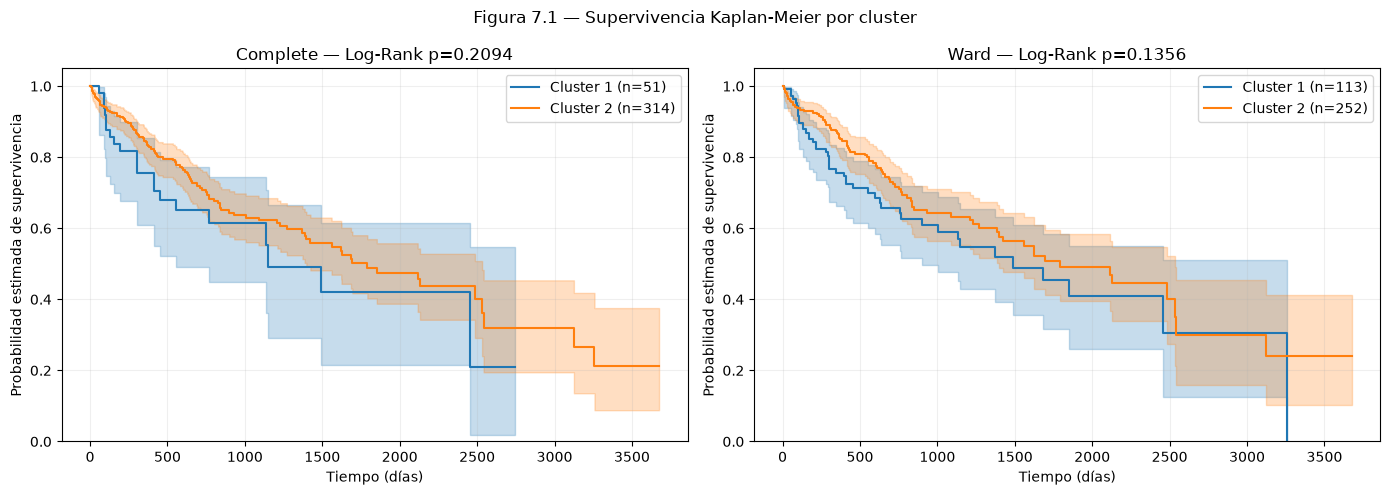

RESULTADOS DE SUPERVIVENCIA


,Modelo,Log-Rank,p-value
0,Complete,1.57580,0.20937
1,Ward,2.22709,0.13561


In [42]:

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt

resultados_supervivencia = []

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metodo in zip(axes, ["Complete", "Ward"]):

    for cluster in [1, 2]:

        grupo = datos_supervivencia[
            datos_supervivencia[metodo] == cluster
        ]

        kmf = KaplanMeierFitter()

        kmf.fit(
            durations=grupo["OS.time"],
            event_observed=grupo["OS"],
            label=f"Cluster {cluster} (n={len(grupo)})"
        )

        kmf.plot_survival_function(
            ax=ax,
            ci_show=True
        )

    # Comparación estadística entre clusters
    grupo_1 = datos_supervivencia[
        datos_supervivencia[metodo] == 1
    ]

    grupo_2 = datos_supervivencia[
        datos_supervivencia[metodo] == 2
    ]

    prueba = logrank_test(
        grupo_1["OS.time"],
        grupo_2["OS.time"],
        event_observed_A=grupo_1["OS"],
        event_observed_B=grupo_2["OS"]
    )

    resultados_supervivencia.append({
        "Modelo": metodo,
        "Log-Rank": prueba.test_statistic,
        "p-value": prueba.p_value
    })

    ax.set_title(
        f"{metodo} — Log-Rank p={prueba.p_value:.4f}"
    )
    ax.set_xlabel("Tiempo (días)")
    ax.set_ylabel("Probabilidad estimada de supervivencia")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.2)

fig.suptitle("Figura 7.1 — Supervivencia Kaplan-Meier por cluster")
plt.tight_layout()
plt.show()

tabla_supervivencia = pd.DataFrame(
    resultados_supervivencia
)

print("RESULTADOS DE SUPERVIVENCIA")
display(tabla_supervivencia.round(5))



### Interpretación del análisis de supervivencia

Se utilizaron curvas Kaplan-Meier y la prueba Log-Rank para comparar la supervivencia de los clusters identificados por Complete y Ward.

En Complete, el primer cluster presentó una supervivencia estimada generalmente menor durante parte del seguimiento. Sin embargo, la prueba Log-Rank obtuvo un valor p de 0.2094, por lo que no se encontraron diferencias estadísticamente significativas.

En Ward se observó una tendencia similar, con una menor supervivencia estimada en el primer cluster durante los primeros años. La prueba Log-Rank obtuvo un valor p de 0.1356, que tampoco representa una diferencia significativa con el nivel de 0.05.

Los intervalos de confianza se amplían hacia el final de ambas gráficas, debido a la menor cantidad de pacientes que permanecen bajo seguimiento.

En general, los resultados no permiten concluir que las agrupaciones moleculares estén asociadas con diferencias en supervivencia. Aunque se observan algunas tendencias, estas no cuentan con suficiente evidencia estadística.

Por lo tanto, la interpretación clínica de los clusters deberá apoyarse principalmente en las diferencias de edad, sexo y patrones de expresión génica identificados previamente.



# 8. Comparación con investigaciones científicas

### Comparación con el estudio TCGA (2017)

The Cancer Genome Atlas Research Network (2017) realizó un análisis molecular del carcinoma hepatocelular utilizando diferentes tipos de información genómica. Mediante la integración de estos datos, los investigadores identificaron tres subgrupos moleculares.

Uno de estos grupos, denominado iCluster 1, presentó una mayor asociación con pacientes jóvenes y mujeres, además de características relacionadas con tumores menos diferenciados.

Al comparar estos resultados con nuestro proyecto, encontramos algunas similitudes con Ward. El primer cluster de este modelo presentó una edad promedio menor y una proporción más alta de mujeres, con diferencias estadísticamente significativas después de la corrección por comparaciones múltiples.

Otra coincidencia se encuentra en la supervivencia. The Cancer Genome Atlas Research Network (2017) no identificó diferencias significativas de supervivencia entre los grupos dentro de la cohorte TCGA, aunque sí encontró diferencias en cohortes externas. En nuestro análisis tampoco encontramos diferencias significativas mediante la prueba Log-Rank.

### Interpretación de los patrones moleculares

Yamashita et al. (2008) estudiaron la expresión de EPCAM y AFP en pacientes con carcinoma hepatocelular. Sus resultados permitieron identificar subgrupos tumorales con características relacionadas con diferentes etapas de maduración de las células hepáticas.

Por otra parte, Hoshida et al. (2009) identificaron tres clases moleculares de carcinoma hepatocelular. Una de ellas, denominada S3, presentó características relacionadas con la diferenciación de los hepatocitos y la conservación de funciones propias del hígado.

En nuestro análisis, Ward identificó un primer cluster con mayor expresión relativa de EPCAM y KRT19, mientras que el segundo presentó mayor expresión de genes relacionados con funciones metabólicas hepáticas, como CYP3A4, CYP2A6 y CYP8B1.

Estos resultados sugieren que algunas de las diferencias moleculares encontradas podrían estar relacionadas con distintos estados de diferenciación celular, similares a los descritos por Yamashita et al. (2008) y Hoshida et al. (2009).

### Discusión de los resultados

La comparación con la literatura muestra que algunas características de nuestros clusters coinciden con patrones moleculares y clínicos descritos anteriormente para el carcinoma hepatocelular.

En particular, Ward identificó diferencias relacionadas con la edad, el sexo y la expresión de genes que también aparecen en investigaciones sobre subgrupos moleculares de esta enfermedad.

Sin embargo, nuestro análisis utiliza únicamente expresión génica y genera dos grupos, mientras que el estudio de The Cancer Genome Atlas Research Network (2017) integró diferentes plataformas moleculares e identificó tres.

Por esta razón, no podemos establecer una correspondencia directa entre nuestros clusters y los subgrupos descritos en las investigaciones.

Aun así, los resultados muestran que el aprendizaje no supervisado permite identificar diferencias moleculares entre tumores y encontrar patrones que pueden relacionarse con características clínicas.



# 9. Evaluación de estabilidad de los modelos

### Estabilidad mediante remuestreo de pacientes

Para evaluar la consistencia de los clusters obtenidos mediante Complete y Ward, se realizará una prueba de estabilidad utilizando subconjuntos aleatorios de pacientes.

En cada repetición se seleccionará el 80% de las muestras tumorales y se volverá a ejecutar el clustering jerárquico con ambos métodos.

Las nuevas agrupaciones se compararán con las originales mediante el Adjusted Rand Index (ARI), que mide la similitud entre dos agrupaciones sin depender de las etiquetas asignadas a los clusters.

El procedimiento se repetirá 100 veces para analizar la variación de los resultados.

Un ARI elevado indicará que las agrupaciones se mantienen relativamente consistentes cuando cambia el conjunto de pacientes utilizado.


In [ ]:

from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import adjusted_rand_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuración del experimento
n_repeticiones = 100
proporcion_muestras = 0.80
semilla = 10

rng = np.random.default_rng(semilla)

X_array = X_reducido.to_numpy()
n_pacientes = X_array.shape[0]
n_submuestra = int(n_pacientes * proporcion_muestras)

# Agrupaciones originales
modelos_estabilidad = {
    "Complete": {
        "metodo": "complete",
        "etiquetas": np.asarray(labels_complete)
    },
    "Ward": {
        "metodo": "ward",
        "etiquetas": np.asarray(labels_ward)
    }
}

resultados_estabilidad = []

for repeticion in range(n_repeticiones):

    # Seleccionar el mismo subconjunto para ambos modelos
    indices = rng.choice(
        n_pacientes,
        size=n_submuestra,
        replace=False
    )

    X_sub = X_array[indices]

    for nombre, configuracion in modelos_estabilidad.items():

        # Volver a ejecutar clustering con el subconjunto
        Z_sub = linkage(
            X_sub,
            method=configuracion["metodo"],
            metric="euclidean"
        )

        etiquetas_sub = fcluster(
            Z_sub,
            t=2,
            criterion="maxclust"
        )

        # Comparar con las etiquetas originales
        # de esos mismos pacientes
        etiquetas_originales = configuracion["etiquetas"][indices]

        ari = adjusted_rand_score(
            etiquetas_originales,
            etiquetas_sub
        )

        resultados_estabilidad.append({
            "Repetición": repeticion + 1,
            "Modelo": nombre,
            "ARI": ari
        })

estabilidad_df = pd.DataFrame(resultados_estabilidad)

# Resumen estadístico
resumen_estabilidad = (
    estabilidad_df.groupby("Modelo")["ARI"]
    .agg(["mean", "std", "median", "min", "max"])
    .round(4)
)

print("ESTABILIDAD DE LOS MODELOS")
print(f"Repeticiones: {n_repeticiones}")
print(f"Pacientes por repetición: {n_submuestra}")

display(resumen_estabilidad)


ESTABILIDAD DE LOS MODELOS
Repeticiones: 100
Pacientes por repetición: 296


,mean,std,median,min,max
Modelo,,,,,
Complete,0.6785,0.1633,0.6883,-0.0182,0.9600
Ward,0.5472,0.2156,0.5844,0.0409,0.8933


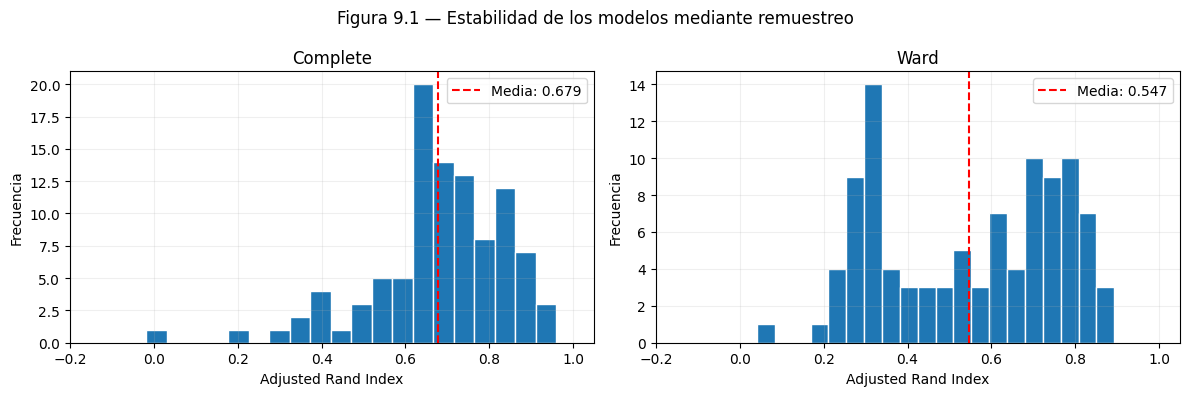

In [44]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metodo in zip(axes, ["Complete", "Ward"]):

    valores = estabilidad_df.loc[
        estabilidad_df["Modelo"] == metodo,
        "ARI"
    ]

    ax.hist(
        valores,
        bins=20,
        edgecolor="white"
    )

    ax.axvline(
        valores.mean(),
        color="red",
        linestyle="--",
        label=f"Media: {valores.mean():.3f}"
    )

    ax.set_title(metodo)
    ax.set_xlabel("Adjusted Rand Index")
    ax.set_ylabel("Frecuencia")
    ax.set_xlim(-0.2, 1.05)
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle("Figura 9.1 — Estabilidad de los modelos mediante remuestreo")

plt.tight_layout()
plt.show()



### Interpretación de la estabilidad de los modelos

Se realizaron 100 repeticiones utilizando aleatoriamente el 80% de los pacientes en cada una. Las agrupaciones obtenidas se compararon con las originales mediante Adjusted Rand Index (ARI).

Complete obtuvo un ARI promedio de 0.6785, con una desviación estándar de 0.1633. Por su parte, Ward alcanzó un promedio de 0.5472 y una desviación estándar de 0.2156.

La Figura 9.1 muestra que Complete presenta una mayor concentración de resultados entre aproximadamente 0.6 y 0.9, mientras que Ward tiene una distribución más dispersa.

Esto indica que Complete conserva sus agrupaciones con mayor consistencia al modificar las muestras utilizadas. Sin embargo, Complete llegó a presentar un ARI ligeramente negativo y Ward obtuvo valores cercanos a cero en algunas repeticiones, lo que demuestra que sus agrupaciones no son completamente estables.

En general, Complete presentó mejores resultados de estabilidad y separación según Silhouette Score, mientras que Ward mostró mayor coincidencia con K-Means y asociaciones clínicas más evidentes con la edad y el sexo.

La prueba de estabilidad permite complementar la evaluación de los modelos, mostrando que no siempre el método con mejores asociaciones clínicas es el que genera las agrupaciones más estables.



# 10. Selección del modelo final

### Comparación y selección

Después de evaluar K-Means y los métodos jerárquicos Complete y Ward, se seleccionó Hierarchical Clustering con Ward, distancia euclidiana y dos clusters como modelo final.

Complete obtuvo el mayor Silhouette Score (0.2089) y presentó una mayor estabilidad durante el remuestreo, con un ARI promedio de 0.6785. Sin embargo, sus grupos fueron considerablemente desiguales, con 51 y 320 pacientes.

Por otro lado, Ward obtuvo un Silhouette Score de 0.1478 y un ARI promedio de estabilidad de 0.5472. Aunque estos resultados fueron inferiores a los de Complete, Ward presentó una mayor coincidencia con K-Means, alcanzando un ARI de 0.4543 frente al 0.1885 de Complete.

Además, Ward identificó dos grupos de 119 y 252 pacientes, con diferencias moleculares que pudieron relacionarse con características clínicas. Después de la corrección por comparaciones múltiples, se encontraron asociaciones estadísticamente significativas con la edad y el sexo.

En el análisis molecular, el primer cluster presentó mayor expresión relativa de genes como EPCAM, KRT19 y SPINT1, mientras que el segundo mostró mayor expresión de genes relacionados con funciones metabólicas hepáticas, como HPD, CYP2A6 y CYP8B1.

Estas diferencias mostraron algunas similitudes con investigaciones anteriores sobre subgrupos moleculares del carcinoma hepatocelular, especialmente con las características descritas por The Cancer Genome Atlas Research Network (2017), Yamashita et al. (2008) y Hoshida et al. (2009).

### Justificación de la decisión

Se decidió priorizar Ward porque el objetivo principal del proyecto es identificar posibles subgrupos moleculares que también puedan interpretarse mediante características clínicas.

Aunque Complete presentó mejores métricas de separación y estabilidad, Ward permitió obtener grupos más equilibrados, mayor coincidencia con K-Means y asociaciones clínicas más claras.

Es importante señalar que la separación de Ward fue relativamente débil y que no se encontraron diferencias estadísticamente significativas de supervivencia entre sus clusters.

Por lo tanto, los dos grupos obtenidos se interpretan como posibles subgrupos moleculares exploratorios, no como subtipos clínicos confirmados.


In [45]:

# Modelo final: Hierarchical Clustering - Ward
modelo_final = "Ward"
k_final = 2

# Crear tabla de asignaciones finales
clusters_finales = pd.DataFrame({
    "Muestra": X_reducido.index,
    "Cluster": labels_ward
})

# Incorporar nombres descriptivos
clusters_finales["Grupo"] = clusters_finales["Cluster"].map({
    1: "Grupo molecular 1",
    2: "Grupo molecular 2"
})

print("MODELO FINAL")
print("Algoritmo: Hierarchical Clustering")
print("Método: Ward")
print("Distancia: Euclidiana")
print("Clusters:", k_final)

print("\nDISTRIBUCIÓN FINAL DE PACIENTES")
display(
    clusters_finales["Grupo"]
    .value_counts()
    .rename_axis("Grupo")
    .reset_index(name="Pacientes")
)

display(clusters_finales.head())


MODELO FINAL
Algoritmo: Hierarchical Clustering
Método: Ward
Distancia: Euclidiana
Clusters: 2

DISTRIBUCIÓN FINAL DE PACIENTES


,Grupo,Pacientes
0,Grupo molecular 2,252
1,Grupo molecular 1,119


,Muestra,Cluster,Grupo
0,TCGA-5R-AA1C-01A,2,Grupo molecular 2
1,TCGA-ED-A66Y-01A,1,Grupo molecular 1
2,TCGA-DD-AAEI-01A,2,Grupo molecular 2
3,TCGA-ED-A8O5-01A,1,Grupo molecular 1
4,TCGA-DD-AACH-01A,1,Grupo molecular 1



### Caracterización de los grupos moleculares

A partir de los patrones de expresión génica identificados mediante Ward, se propusieron nombres descriptivos para los dos clusters.

**Cluster 1 — Perfil progenitor/epitelial (119 pacientes)**

Este grupo presentó mayor expresión relativa de genes como EPCAM, KRT19 y SPINT1. Los dos primeros se han relacionado con características de células progenitoras y perfiles epiteliales en el carcinoma hepatocelular (Yamashita et al., 2008).

Además, los pacientes de este grupo presentaron una edad promedio menor y una proporción más alta de mujeres.

**Cluster 2 — Perfil hepatocitario/metabólico (252 pacientes)**

Este grupo presentó mayor expresión relativa de genes como HPD, CYP2A6, CYP8B1 y TAT, relacionados con funciones metabólicas del hígado.

Este patrón podría estar relacionado con características de hepatocitos más diferenciados, similares a las descritas por Hoshida et al. (2009).

Los nombres propuestos buscan describir las principales diferencias moleculares encontradas. No representan subtipos clínicos confirmados.



# 11. Limitaciones del estudio

Aunque el proyecto permitió identificar diferencias moleculares y algunas asociaciones clínicas entre pacientes con cáncer de hígado, existen limitaciones que deben considerarse al interpretar los resultados.

### Tamaño y disponibilidad de los datos

El análisis se realizó con 371 tumores primarios de la cohorte TCGA-LIHC. Aunque se contó con información clínica para todos los pacientes, solamente 365 tenían registros de supervivencia.

Además, algunas variables clínicas presentaron información incompleta. Por ejemplo, el grado tumoral no tenía valores disponibles, por lo que no fue posible evaluar su relación con los clusters.

### Selección de genes y reducción de dimensionalidad

Para reducir la cantidad de variables se eliminaron genes con expresión detectable en menos del 5% de las muestras y posteriormente se conservó el 20% de los genes con mayor varianza.

Aunque estos filtros permitieron trabajar con una cantidad más manejable de genes, también pudieron eliminar información molecular relevante.

Posteriormente, PCA redujo los 8,837 genes seleccionados a 85 componentes principales, conservando al menos el 80% de la varianza. Esto significa que una parte de la variabilidad original no se utilizó durante el clustering.

### Separación y estabilidad de los clusters

El modelo seleccionado, Hierarchical Clustering con Ward, obtuvo un Silhouette Score de 0.1478, lo que indica que sus dos grupos presentan una separación relativamente débil.

Además, durante la evaluación de estabilidad mediante 100 remuestreos, Ward obtuvo un ARI promedio de 0.5472. Esto muestra que las agrupaciones pueden cambiar cuando se modifica el conjunto de pacientes utilizado.

Por lo tanto, los clusters identificados no deben considerarse subtipos moleculares completamente definidos.

### Interpretación clínica y supervivencia

Aunque Ward presentó asociaciones estadísticamente significativas con la edad y el sexo, estas diferencias no demuestran que las características moleculares sean su causa.

En el análisis de supervivencia tampoco se encontraron diferencias estadísticamente significativas entre los grupos mediante la prueba Log-Rank (p = 0.1356).

Además, los análisis clínicos fueron exploratorios y no se ajustaron por posibles factores de confusión, como la edad, el sexo o el estadio de la enfermedad.

### Validación de los resultados

El proyecto utilizó únicamente información de expresión génica de la cohorte TCGA-LIHC para construir los clusters.

No se utilizaron cohortes externas para comprobar si las agrupaciones se reproducen en otros pacientes. Tampoco se realizó una validación experimental de los genes identificados.

Por esta razón, los resultados deben interpretarse como hallazgos exploratorios que permiten proponer posibles diferencias moleculares, pero no confirmar nuevos subtipos clínicos de cáncer de hígado.



# 12. Conclusiones generales

El objetivo de este proyecto fue identificar posibles subgrupos moleculares de cáncer de hígado mediante técnicas de aprendizaje no supervisado, utilizando datos de expresión génica de la cohorte TCGA-LIHC.

Inicialmente se analizaron 60,660 genes de 371 tumores primarios. Después de revisar la calidad de los datos y aplicar filtros de expresión y variabilidad, se conservaron 8,837 genes. Posteriormente, PCA permitió reducir esta información a 85 componentes principales, conservando al menos el 80% de la varianza.

Se evaluaron los algoritmos K-Means y Hierarchical Clustering, utilizando los métodos Complete y Ward. Después de comparar la separación, estabilidad, coincidencia entre modelos y características clínicas, se seleccionó Ward con distancia euclidiana y dos clusters.

El modelo final identificó dos posibles perfiles moleculares:

**Cluster 1 — Perfil progenitor/epitelial (119 pacientes):**

Este grupo presentó mayor expresión relativa de genes como EPCAM, KRT19 y SPINT1, relacionados con características epiteliales y, en el caso de EPCAM y KRT19, con células progenitoras hepáticas. Además, los pacientes de este grupo presentaron una edad promedio menor y una proporción más alta de mujeres.

**Cluster 2 — Perfil hepatocitario/metabólico (252 pacientes):**

Este grupo presentó mayor expresión relativa de genes como HPD, CYP2A6, CYP8B1 y TAT, relacionados con funciones metabólicas del hígado. Este patrón podría indicar que los tumores conservan algunas características de hepatocitos más diferenciados.

Los perfiles identificados muestran similitudes con características moleculares descritas en investigaciones anteriores sobre carcinoma hepatocelular (Yamashita et al., 2008; Hoshida et al., 2009).

En la evaluación clínica, Ward presentó asociaciones estadísticamente significativas con la edad y el sexo después de aplicar la corrección por comparaciones múltiples. Sin embargo, no se encontraron diferencias significativas de supervivencia entre los dos clusters mediante la prueba Log-Rank (p = 0.1356).

Aunque Ward permitió identificar grupos con características moleculares y clínicas interesantes, presentó un Silhouette Score de 0.1478 y un ARI promedio de estabilidad de 0.5472. Estos resultados indican que la separación y consistencia de las agrupaciones son limitadas.

Además, el análisis se realizó únicamente con pacientes de TCGA-LIHC, sin validación en cohortes externas. Por esta razón, los nombres propuestos son descriptivos y no representan subtipos clínicos confirmados.

En conclusión, el proyecto permitió identificar dos posibles perfiles moleculares de carcinoma hepatocelular: uno con mayor expresión de marcadores progenitores y epiteliales, y otro relacionado con funciones metabólicas hepáticas.

Los resultados muestran que el aprendizaje no supervisado puede ayudar a identificar patrones de expresión génica y relacionarlos con características clínicas, aunque se necesitan estudios adicionales para confirmar su relevancia biológica y clínica.

Finalmente, este proyecto permitió comprender cómo combinar filtrado de genes, PCA y clustering para analizar datos de alta dimensionalidad, así como la importancia de evaluar la estabilidad, interpretar los resultados y reconocer las limitaciones antes de establecer conclusiones.



# 13. Referencias bibliográficas

Goldman, M. J., Craft, B., Hastie, M., Repečka, K., McDade, F., Kamath, A., Banerjee, A., Luo, Y., Rogers, D., Brooks, A. N., Zhu, J., & Haussler, D. (2020). Visualizing and interpreting cancer genomics data via the Xena platform. *Nature Biotechnology, 38*, 675–678. https://doi.org/10.1038/s41587-020-0546-8

Hoshida, Y., Nijman, S. M. B., Kobayashi, M., Chan, J. A., Brunet, J.-P., Chiang, D. Y., Villanueva, A., Newell, P., Ikeda, K., Hashimoto, M., Watanabe, G., Gabriel, S., Friedman, S. L., Kumada, H., Llovet, J. M., & Golub, T. R. (2009). Integrative transcriptome analysis reveals common molecular subclasses of human hepatocellular carcinoma. *Cancer Research, 69*(18), 7385–7392. https://doi.org/10.1158/0008-5472.CAN-09-1089

Khan Academy. (s.f.). *Interquartile range (IQR) review*. https://www.khanacademy.org/math/cc-sixth-grade-math/cc-6th-data-statistics/cc-6th/a/interquartile-range-review

National Institute of Standards and Technology. (s.f.). *What are outliers in the data?* NIST/SEMATECH e-Handbook of Statistical Methods. https://itl.nist.gov/div898/handbook/prc/section1/prc16.htm

The Cancer Genome Atlas Research Network. (2017). Comprehensive and integrative genomic characterization of hepatocellular carcinoma. *Cell, 169*(7), 1327–1341.e23. https://doi.org/10.1016/j.cell.2017.05.046

UCSC Xena. (s.f.). *GDC TCGA Liver Cancer (LIHC)* [Conjunto de datos]. https://xenabrowser.net/datapages/?cohort=GDC%20TCGA%20Liver%20Cancer%20%28LIHC%29

Yamashita, T., Forgues, M., Wang, W., Kim, J. W., Ye, Q., Jia, H., Budhu, A., Zanetti, K. A., Chen, Y., Qin, L.-X., Tang, Z.-Y., & Wang, X. W. (2008). EpCAM and alpha-fetoprotein expression defines novel prognostic subtypes of hepatocellular carcinoma. *Cancer Research, 68*(5), 1451–1461. https://doi.org/10.1158/0008-5472.CAN-07-6013


La inteligencia artificial se utilizó principalmente para apoyar en la elaboración y corrección del código Python, explicar el funcionamiento de los algoritmos, sugerir métodos de análisis y facilitar la búsqueda e interpretación de investigaciones científicas relacionadas con el carcinoma hepatocelular.

Doy mi palabra que he realizado esta actividad con integridad académica.